# 온라인 쇼핑몰 구매 의도 예측 미니 프로젝트

## 프로젝트 주제
Online Shoppers Purchasing Intention 데이터를 이용하여 온라인 쇼핑 고객의 세션 행동과 실제 구매 여부를 분석하고 구매 여부를 예측해본다.

### 이 프로젝트에서 궁금한 점

온라인 쇼핑을 할 때 사람들은 상품을 많이 보기도 하고, 오래 머물기도 하며, 바로 사이트를 나가기도 한다.

나는 이런 행동들이 실제 구매 여부와 어떤 관계가 있는지 궁금하다.

특히 다음 내용을 데이터를 보면서 하나씩 확인해보고 싶다.

- 상품 페이지를 많이 보는 사람은 실제로 구매를 더 많이 하는가?
- 상품 페이지를 오래 보는 사람은 구매를 더 많이 하는가?
- PageValues는 실제 구매 여부와 어느 정도 관련이 있는가?
- 사이트에서 빨리 이탈하는 사람은 실제 구매가 적은가?
- 신규 방문자와 재방문자의 구매 행동은 다른가?
- 주말과 평일에 구매 행동이 다른가?
- 특정 월에 구매가 더 많이 발생하는가?
- 어떤 Feature가 구매 여부를 구분하는 데 가장 도움이 될까?

분석 결과를 바탕으로 데이터를 전처리하고 여러 모델을 직접 비교하여 최종적으로 구매 여부를 잘 예측하는 모델을 선택해본다.

- 문제 유형: Classification(분류 모델)
- Target: Revenue

# 데이터 변수 설명

- Administrative : 계정 관리, 주문 관리 등 관리 목적 페이지를 방문한 횟수
- Administrative_Duration : 관리 목적 페이지에 머문 총 시간
- Informational : 사이트나 상품 관련 정보 제공 페이지를 방문한 횟수
- Informational_Duration : 정보 제공 페이지에 머문 총 시간
- ProductRelated : 상품 관련 페이지를 방문한 횟수
- ProductRelated_Duration : 상품 관련 페이지에 머문 총 시간
- BounceRates : 방문 후 추가 행동 없이 사이트를 이탈하는 정도를 나타내는 지표
- ExitRates : 해당 페이지가 세션의 마지막 페이지가 되는 정도를 나타내는 지표
- PageValues : 구매로 이어지는 과정에서 방문 페이지가 갖는 가치를 나타내는 지표
- SpecialDay : 방문일이 밸런타인데이, 어머니날 등 특정 기념일과 얼마나 가까운지를 나타내는 값
- Month : 방문이 발생한 월
- OperatingSystems : 사용자의 운영체제 종류를 나타내는 코드
- Browser : 사용한 브라우저 종류를 나타내는 코드
- Region : 사용자가 속한 지역을 나타내는 코드
- TrafficType : 사용자가 사이트에 유입된 경로 유형을 나타내는 코드
- VisitorType : 방문자 유형 (Returning_Visitor, New_Visitor 등)
- Weekend : 방문일이 주말인지 여부
- Revenue : 해당 세션에서 실제 구매가 발생했는지 여부(타겟 변수)

# DAY 3. 데이터 이해 및 EDA

데이터 구조와 변수 분포를 확인하고 구매 여부에 따른 차이를 분석한다.

# 1. 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 불러오기

In [2]:
df = pd.read_csv('online_shoppers_intention.csv')
display(df)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


# 3. 데이터 기본 구조 확인

행과 열의 개수, 자료형, 결측치, 기초 통계량을 확인한다.

In [3]:
# 행과 열의 개수 확인
print('행과 열의 개수 :', df.shape)

# 컬럼 명 확인
print('컬럼 명 :', df.columns)

# 앞부분 데이터 확인
print('앞부분 데이터 :')
display(df.head())

# 데이터 타입 확인
print('데이터 타입 :')
df.info()

# 결측치 확인
print('결측치 확인 :')
print(df.isnull().sum())

# 기초 통계량 확인
print('기초 통계량 확인 :')
display(df.describe())

행과 열의 개수 : (12330, 18)
컬럼 명 : Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')
앞부분 데이터 :


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


데이터 타입 :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType  

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


## 데이터 구조를 보고 든 생각

- 데이터 행 개수: 12,330개
- 데이터 열 개수: 18개
- 결측치: 없음
- 한 행이 의미하는 것: 한 사용자의 웹사이트 방문 세션들을 표현한것으로 보임 
- Target: Revenue
- 처음 데이터를 보고 이상 한점 : 수치형 변수뿐만 아니라 Month, VisitorType과 같은 범주형 변수도 포함되어 있어 이후 전처리가 필요해 보인다.

# 4. 수치형 변수와 범주형 변수 확인

In [4]:
# 수치형 변수 확인 
print('수치형 변수:' ,df.select_dtypes(include=['int64', 'float64']).columns) 
# 범주형 변수 확인 
print('범주형 변수:' ,df.select_dtypes(include='object').columns )
# bool 형태의 변수 확인
print('bool 형태의 변수:', df.select_dtypes(include='bool').columns)


수치형 변수: Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType'],
      dtype='object')
범주형 변수: Index(['Month', 'VisitorType'], dtype='object')
bool 형태의 변수: Index(['Weekend', 'Revenue'], dtype='object')


## Feature 확인 결과

- Numerical Feature(수치형 변수): Administrative, Administrative_Duration, Informational, Informational_Duration, ProductRelated, ProductRelated_Duration, BounceRates, ExitRates, PageValues, SpecialDay

- Categorical Feature(범주형 변수): Month, OperatingSystems, Browser, Region, TrafficType, VisitorType, Weekend

- Encoding(범주형 데이터 변환)이 필요할 것 같은 Feature: Month, OperatingSystems, Browser, Region, TrafficType, VisitorType
  - 이유: 문자이거나 숫자로 되어 있어도 실제로는 종류를 구분하는 범주형 변수이기 때문이다.

- Scaling(데이터 크기 조정)이 필요할 것 같은 Feature: Administrative, Administrative_Duration, Informational, Informational_Duration, ProductRelated, ProductRelated_Duration, BounceRates, ExitRates, PageValues, SpecialDay
  - 이유: 수치형 변수마다 값의 범위가 다르기 때문에 모델링할 때 Scaling(데이터 크기 조정)이 필요할 수 있다.

- 서로 비슷한 의미를 가진 것 같은 Feature: ProductRelated와 ProductRelated_Duration, BounceRates와 ExitRates
  - 이유: 각각 상품 페이지의 방문 행동과 사이트 이탈 행동을 나타내는 변수이기 때문이다.

# 5. 구매 여부 분포 확인

Revenue별 세션 수와 비율을 비교한다.

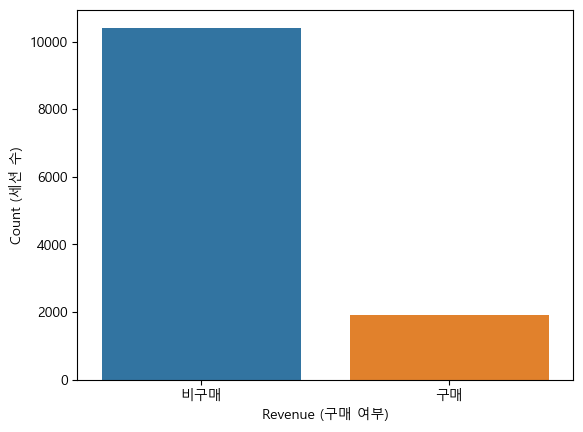

False    84.525547
True     15.474453
Name: Revenue, dtype: float64

In [5]:
# Revenue 구매 여부별 세션 수 그래프
sns.countplot(data=df, x='Revenue')

plt.xlabel('Revenue (구매 여부)')
plt.ylabel('Count (세션 수)')
plt.xticks([0, 1], ['비구매', '구매'])

plt.show()

# 구매 여부별 세션 수
df['Revenue'].value_counts()

# 구매 여부별 비율(%)
df['Revenue'].value_counts(normalize=True) * 100

## Revenue 확인 결과
- 구매(True): 약 1,892개
- 비구매(False): 약 10,338개
- 구매 비율: 약 15.474%
- 비구매 비율: 약 84.525%
- 데이터가 균형적이라고 생각하는가?: 구매 비용보다 비구매 비율이 훨씬 높기 때문에 불균형하다고 생각한다.
- 모델을 만들 때 신경 써야 할 점: 데이터가 불균형하기 때문에 Accuracy(정확도)만 확인하는거 보다 Precision(정밀도), Recall(재현율), F1-score(F1 점수)들도 여러가지 확인해 볼필요가 있어 보인다.

# 6. 주요 변수 분포 확인

상품 페이지 방문 횟수, 체류 시간, PageValues, BounceRates, ExitRates의 분포를 확인한다.

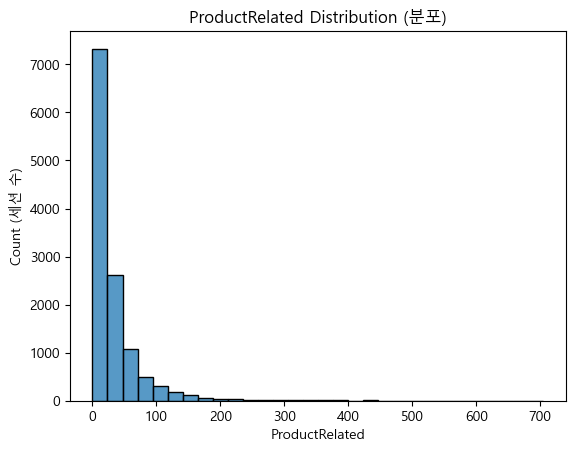

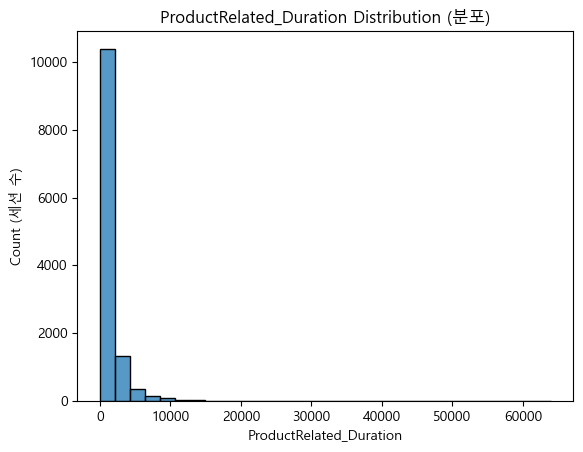

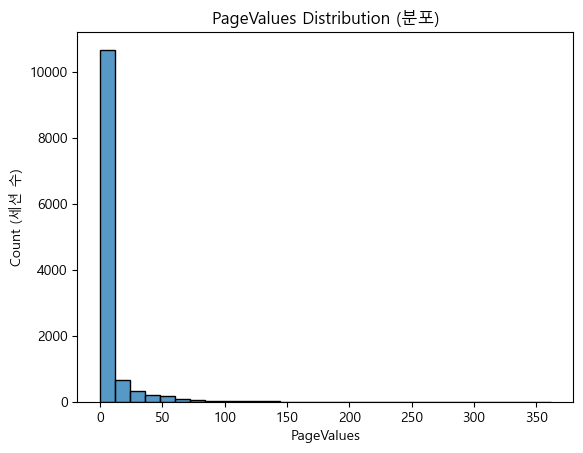

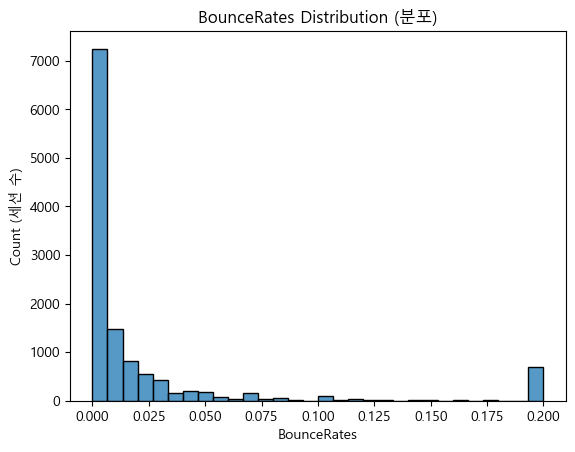

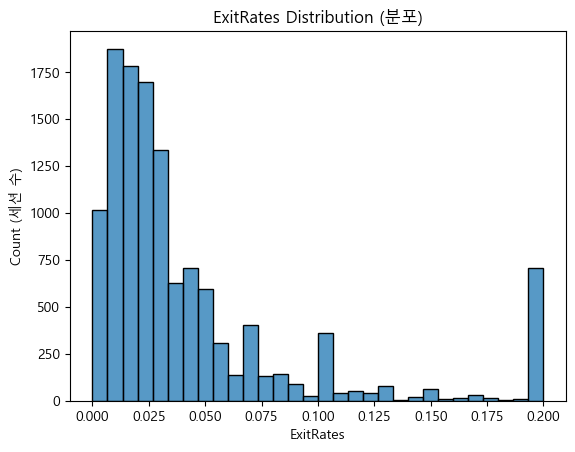

In [6]:
# 주요 Feature의 분포 확인
features = ['ProductRelated', 'ProductRelated_Duration', 'PageValues', 'BounceRates', 'ExitRates']

for feature in features:
    sns.histplot(data=df, x=feature, bins=30)
    plt.title(feature + ' Distribution (분포)')
    plt.xlabel(feature)
    plt.ylabel('Count (세션 수)')
    plt.show()


# 7. 상품 페이지 방문 횟수와 구매 여부

ProductRelated를 Revenue에 따라 비교한다.

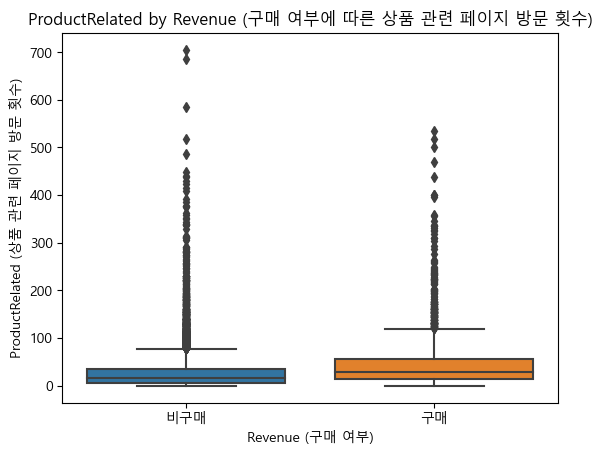

In [7]:
# ProductRelated boxplot 그래프
sns.boxplot(data=df, x='Revenue', y='ProductRelated')

plt.title('ProductRelated by Revenue (구매 여부에 따른 상품 관련 페이지 방문 횟수)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('ProductRelated (상품 관련 페이지 방문 횟수)')

plt.xticks([0, 1], ['비구매', '구매'])

plt.show()

## 결과 정리

### ProductRelated (상품 관련 페이지 방문 횟수)
- 구매(True)한 경우가 비구매(False)한 경우보다 전체적으로 상품 관련 페이지를 더 많이 방문하는 것으로 보인다.
- 두 경우 모두 방문 횟수가 매우 큰 이상치가 많이 보인다.

# 8. 상품 페이지 체류 시간과 구매 여부

ProductRelated_Duration을 Revenue에 따라 비교한다.

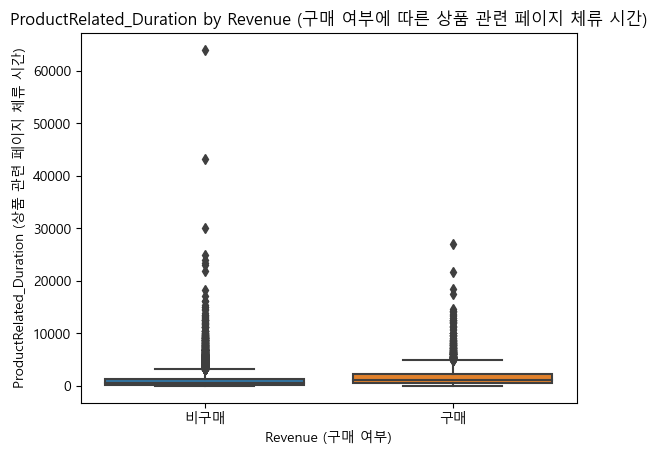

In [8]:
# ProductRelated_Duration boxplot 그래프
sns.boxplot(data=df, x='Revenue', y='ProductRelated_Duration')

plt.title('ProductRelated_Duration by Revenue (구매 여부에 따른 상품 관련 페이지 체류 시간)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('ProductRelated_Duration (상품 관련 페이지 체류 시간)')

plt.xticks([0, 1], ['비구매', '구매'])

plt.show()

## 결과 정리

### ProductRelated_Duration (상품 관련 페이지 체류 시간)
- 구매(True)한 경우가 비구매(False)한 경우보다 상품 관련 페이지에 머무는 시간이 전체적으로 더 긴 것으로 보인다.
- 체류 시간이 매우 큰 이상치가 많이 보인다.

# 9. PageValues와 구매 여부

PageValues를 Revenue에 따라 비교한다.

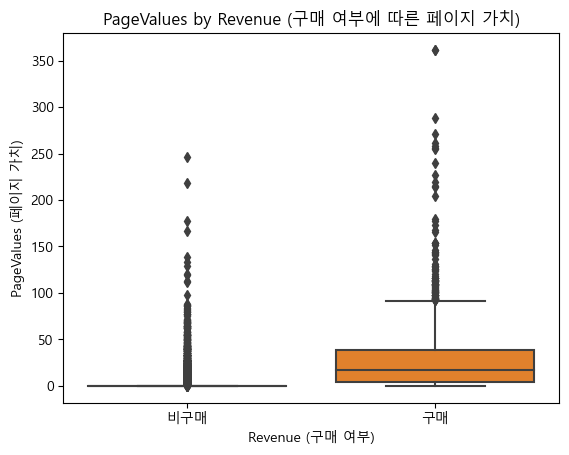

In [9]:
# PageValues boxplot 그래프
sns.boxplot(data=df, x='Revenue', y='PageValues')

plt.title('PageValues by Revenue (구매 여부에 따른 페이지 가치)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('PageValues (페이지 가치)')

plt.xticks([0, 1], ['비구매', '구매'])

plt.show()

## 결과 정리

### PageValues (페이지 가치)
- 구매(True)한 경우의 PageValues가 비구매(False)보다 확실히 높은 모습을 보인다.
- 지금까지 확인한 Feature 중 구매 여부에 따른 차이가 가장 눈에 띄는 것 같다.

# 10. 상품 탐색 행동 비교

ProductRelated, ProductRelated_Duration, PageValues의 차이를 비교한다.

In [10]:
# 구매 여부에 따른 평균 확인
df.groupby('Revenue')[['ProductRelated',
                       'ProductRelated_Duration',
                       'PageValues']].mean()

# 구매 여부에 따른 중앙값 확인
df.groupby('Revenue')[['ProductRelated',
                       'ProductRelated_Duration',
                       'PageValues']].median()

,ProductRelated,ProductRelated_Duration,PageValues
Revenue,,,
False,16.0,510.19000,0.000000
True,29.0,1109.90625,16.758134


## 세 가지를 비교하고 든 생각

- ProductRelated (상품 관련 페이지 방문 횟수): 구매한 경우의 중앙값이 29로 비구매의 16보다 높게 나타났다.

- ProductRelated_Duration (상품 관련 페이지 체류 시간): 구매한 경우의 중앙값이 약 1109.91로 비구매의 약 510.19보다 높게 나타났다.

- PageValues (페이지 가치): 비구매의 중앙값은 0이지만 구매한 경우는 약 16.76으로 차이가 크게 나타났다.

- 이 중 가장 구매 여부와 관련 있어 보이는 Feature (변수): PageValues (페이지 가치)

- 그렇게 생각한 이유: ProductRelated (상품 관련 페이지 방문 횟수)와 ProductRelated_Duration (상품 관련 페이지 체류 시간)도 구매 여부에 따라 차이가 있었지만, PageValues (페이지 가치)는 비구매와 구매의 중앙값 차이가 가장 눈에 띄게 나타났기 때문이다.

# 11. BounceRates와 구매 여부

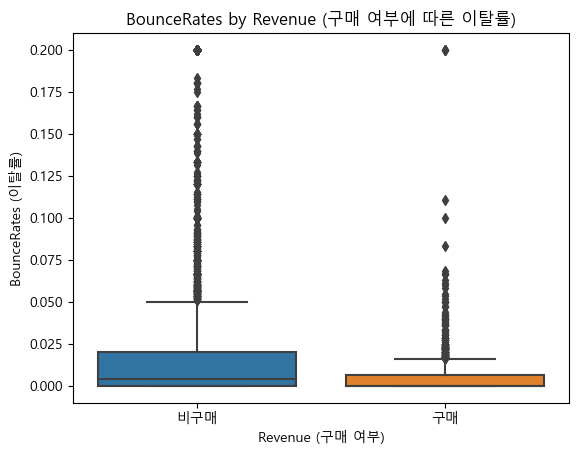

In [11]:
# BounceRates boxplot 그래프
sns.boxplot(data=df, x='Revenue', y='BounceRates')

plt.title('BounceRates by Revenue (구매 여부에 따른 이탈률)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('BounceRates (이탈률)')

# x축 False / True를 비구매 / 구매로 변경
plt.xticks([0, 1], ['비구매', '구매'])

plt.show()

## BounceRates 확인 결과

### BounceRates (이탈률)
- 구매(True)한 경우가 비구매(False)한 경우보다 BounceRates가 낮은 모습을 보인다.

- 사이트에서 빠르게 이탈할수록 구매로 이어지기 어려울 가능성이 있어 보인다.

# 12. ExitRates와 구매 여부

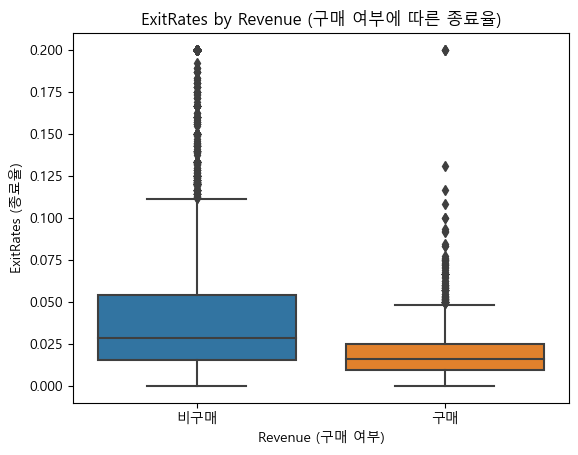

In [12]:
# ExitRates boxplot 그래프
sns.boxplot(data=df, x='Revenue', y='ExitRates')

plt.title('ExitRates by Revenue (구매 여부에 따른 종료율)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('ExitRates (종료율)')

plt.xticks([0, 1], ['비구매', '구매'])

plt.show()

## ExitRates 확인 결과

### ExitRates (종료율)
- 구매(True)한 경우가 비구매(False)한 경우보다 ExitRates가 전체적으로 낮게 나타난다.

- ExitRates가 낮은 세션에서 구매가 더 많이 발생할 가능성이 있어 보인다.

# 13. 방문자 유형별 구매 여부

방문자 유형에 따른 구매 건수와 비율을 비교한다.

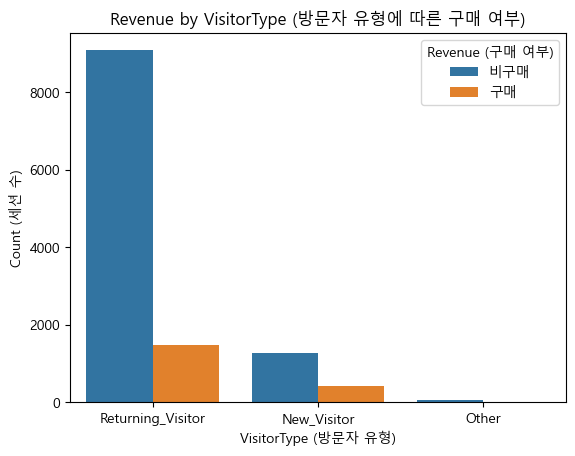

VisitorType별 구매 비율:
VisitorType
New_Visitor          24.911452
Other                18.823529
Returning_Visitor    13.932329
Name: Revenue, dtype: float64


In [13]:
# VisitorType (방문자 유형)에 따른 Revenue (구매 여부) 확인
sns.countplot(data=df, x='VisitorType', hue='Revenue')

plt.title('Revenue by VisitorType (방문자 유형에 따른 구매 여부)')
plt.xlabel('VisitorType (방문자 유형)')
plt.ylabel('Count (세션 수)')

# 범례 표시 변경
plt.legend(title='Revenue (구매 여부)', labels=['비구매', '구매'])

plt.show()

# VisitorType (방문자 유형)별 구매 비율 확인
print("VisitorType별 구매 비율:")
print(df.groupby('VisitorType')['Revenue'].mean() * 100)

## VisitorType (방문자 유형) 확인 결과
- Returning Visitor (재방문자): 전체 방문자 수와 구매한 세션 수는 가장 많았지만, 실제 구매 비율은 약 13.93%로 나타났다.

- New Visitor (신규 방문자): 전체 방문자 수는 재방문자보다 적었지만, 구매 비율은 약 24.91%로 세 유형 중 가장 높게 나타났다.

- Other (기타 방문자): 전체 방문자 수는 매우 적었으며, 구매 비율은 약 18.82%로 나타났다.

- 단순 개수와 구매 비율에서 차이가 있었는가?: 차이가 있었다. 단순 구매 건수만 보면 Returning Visitor (재방문자)가 가장 많았지만, 실제 구매 비율은 New Visitor (신규 방문자)가 가장 높았다.

- 해석: 처음에는 재방문자가 구매를 더 많이 할 것이라고 생각했지만, 구매 비율을 확인해보니 New Visitor (신규 방문자)의 구매 비율이 더 높게 나타났다. 따라서 단순히 구매 건수만 보는 것보다 각 방문자 유형의 전체 세션 수를 고려한 구매 비율을 같이 확인하는 것이 중요해 보인다.

# 14. 주말 여부에 따른 구매 차이

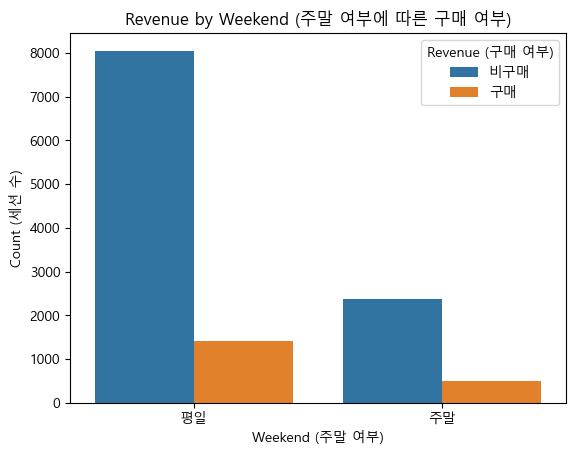

Weekend별 구매 비율:
Weekend
False    14.891144
True     17.398884
Name: Revenue, dtype: float64


In [14]:
# Weekend (주말 여부)에 따른 Revenue (구매 여부) 확인
sns.countplot(data=df, x='Weekend', hue='Revenue')

plt.title('Revenue by Weekend (주말 여부에 따른 구매 여부)')
plt.xlabel('Weekend (주말 여부)')
plt.ylabel('Count (세션 수)')

# X축 표시 변경
plt.xticks([0, 1], ['평일', '주말'])

# 범례 표시 변경
plt.legend(title='Revenue (구매 여부)', labels=['비구매', '구매'])

plt.show()

# Weekend (주말 여부)별 구매 비율 확인
print('Weekend별 구매 비율:')
print(df.groupby('Weekend')['Revenue'].mean() * 100)

## Weekend 확인 결과
- 평일: 구매 비율이 약 14.89%로 나타났다.

- 주말: 구매 비율이 약 17.40%로 나타났다.

- 구매 비율 차이: 주말이 평일보다 약 2.51%p 높게 나타났다.

- 해석: 전체 세션 수는 평일이 더 많았지만, 구매 비율은 주말이 평일보다 조금 더 높게 나타났다. 따라서 Weekend (주말 여부)도 구매 여부와 어느 정도 관련이 있어 보인다.

# 15. 월별 구매 여부

월별 구매 건수와 구매 비율을 확인한다.

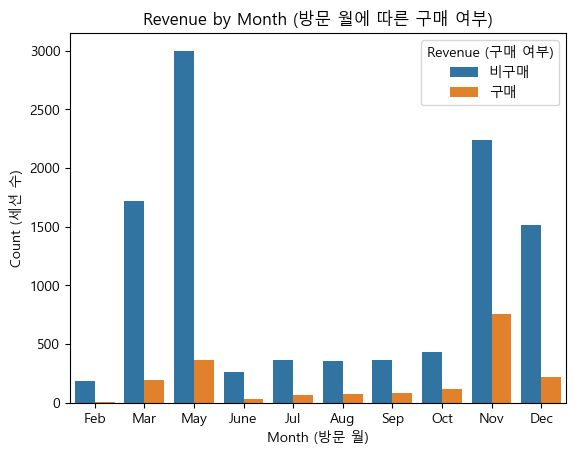

Month별 구매 비율:
Month
Aug     17.551963
Dec     12.507238
Feb      1.630435
Jul     15.277778
June    10.069444
Mar     10.068170
May     10.850178
Nov     25.350233
Oct     20.947177
Sep     19.196429
Name: Revenue, dtype: float64


In [15]:
# Month (방문 월)에 따른 Revenue (구매 여부) 확인
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul',
               'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

sns.countplot(data=df, x='Month', hue='Revenue', order=month_order)

plt.title('Revenue by Month (방문 월에 따른 구매 여부)')
plt.xlabel('Month (방문 월)')
plt.ylabel('Count (세션 수)')

# 범례 표시 변경
plt.legend(title='Revenue (구매 여부)', labels=['비구매', '구매'])

plt.show()

# Month (방문 월)별 구매 비율 확인
print('Month별 구매 비율:')
print(df.groupby('Month')['Revenue'].mean() * 100)

## Month 확인 결과
- 구매가 많이 발생한 월: 11월에 구매 세션이 가장 많이 발생했고, 구매 비율도 약 25.35%로 가장 높게 나타났다.

- 구매가 적게 발생한 월: 2월은 구매 세션 수가 적었으며, 구매 비율도 약 1.63%로 가장 낮게 나타났다.

- 방문량을 고려했을 때 눈에 띄는 월: 11월은 방문량 자체도 많았지만 구매 비율도 약 25.35%로 가장 높았다. 반면 5월은 방문량이 가장 많았지만 구매 비율은 약 10.85%로 나타났다

- 해석: 단순히 방문량이 많다고 해서 구매 비율도 높은 것은 아닌 것으로 보인다. 특히 5월은 방문량이 가장 많았지만 구매 비율은 높지 않았고, 11월은 방문량과 구매 비율이 모두 높게 나타났다. 따라서 Month (방문 월)도 구매 여부와 관련이 있어 보인다.

# 16. SpecialDay와 구매 여부

SpecialDay 값의 분포:
0.0    11079
0.2      178
0.4      243
0.6      351
0.8      325
1.0      154
Name: SpecialDay, dtype: int64


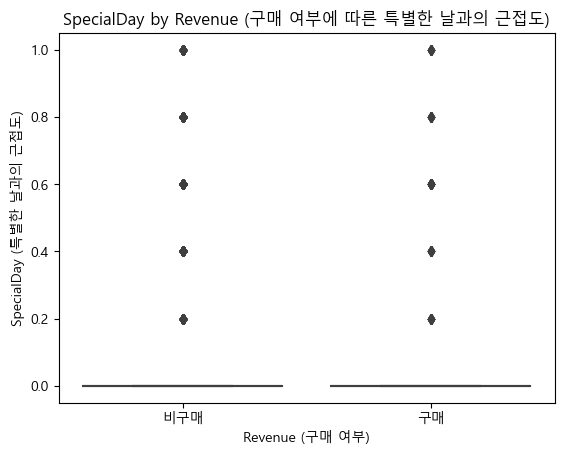

구매 여부에 따른 SpecialDay 평균:
Revenue
False    0.068432
True     0.023166
Name: SpecialDay, dtype: float64


In [16]:
# SpecialDay (특별한 날과의 근접도) 값의 분포 확인
print('SpecialDay 값의 분포:')
print(df['SpecialDay'].value_counts().sort_index())

# Revenue (구매 여부)에 따른 SpecialDay (특별한 날과의 근접도) 확인
sns.boxplot(data=df, x='Revenue', y='SpecialDay')

plt.title('SpecialDay by Revenue (구매 여부에 따른 특별한 날과의 근접도)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('SpecialDay (특별한 날과의 근접도)')

plt.xticks([0, 1], ['비구매', '구매'])

plt.show()

# 구매 여부에 따른 SpecialDay 평균 확인
print('구매 여부에 따른 SpecialDay 평균:')
print(df.groupby('Revenue')['SpecialDay'].mean())

## SpecialDay 확인 결과
- 눈에 띄는 차이: 구매와 비구매 모두 SpecialDay (특별한 날과의 근접도)가 0인 데이터가 대부분이어서 그래프에서 큰 차이가 보이지 않았다.

- 구매 여부와 관련 있어 보이는가?: 지금까지 확인한 그래프만 봤을 때는 구매 여부와 뚜렷한 관련이 있어 보이지 않는다.

- 해석: 전체 12,330개의 세션 중 SpecialDay가 0인 데이터가 11,079개로 대부분을 차지했다. 구매와 비구매 모두 0에 데이터가 많이 몰려 있어 다른 Feature에 비해 구매 여부를 구분하는 차이가 크지 않은 것으로 보인다.

# 17. 변수 간 상관관계

수치형 변수의 상관계수를 히트맵으로 확인한다.

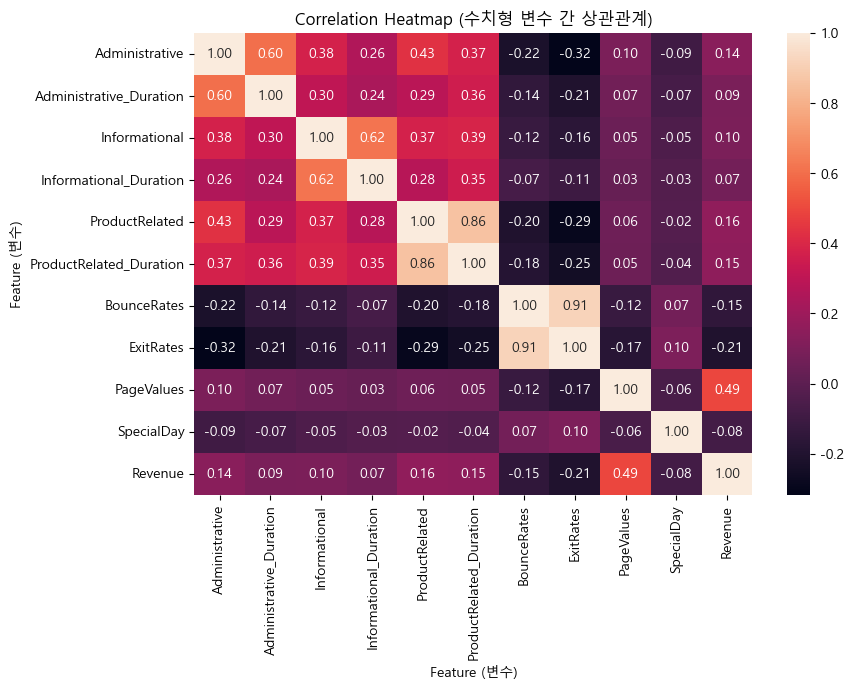

In [17]:
# 상관관계를 확인할 Numerical Feature (수치형 변수)
numeric_features = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay',
    'Revenue'
]

# Correlation (상관계수) 계산
corr = df[numeric_features].corr()

# Heatmap (상관관계 히트맵)
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt='.2f')

plt.title('Correlation Heatmap (수치형 변수 간 상관관계)')
plt.xlabel('Feature (변수)')
plt.ylabel('Feature (변수)')
plt.show()

## Heatmap(상관관계 히트맵) 확인 결과
- ProductRelated (상품 관련 페이지 방문 횟수) ↔ ProductRelated_Duration (상품 관련 페이지 체류 시간): 상관계수가 0.86으로 강한 양의 상관관계가 나타났다. 상품 관련 페이지를 많이 방문할수록 체류 시간도 함께 증가하는 경향이 있는 것으로 보인다.

- BounceRates (이탈률) ↔ ExitRates (종료율): 상관계수가 0.91로 매우 강한 양의 상관관계가 나타났다. 두 Feature (변수)가 서로 비슷하게 움직이는 것으로 보인다.

- 그 외 눈에 띈 관계: Informational (정보 페이지 방문 횟수)과 Informational_Duration (정보 페이지 체류 시간)은 0.62, Administrative (관리 페이지 방문 횟수)와 Administrative_Duration (관리 페이지 체류 시간)은 0.60으로 양의 상관관계가 나타났다.

- 모델링할 때 고려하고 싶은 점: ProductRelated와 ProductRelated_Duration, BounceRates와 ExitRates처럼 상관관계가 높은 Feature들은 서로 비슷한 정보를 가지고 있을 가능성이 있어 모델링할 때 같이 확인해보고 싶다.

- Target (Revenue)과의 관계: Revenue (구매 여부)는 PageValues (페이지 가치)와
상관계수가 0.49로 가장 높은 양의 상관관계가 나타났다. 반면 ExitRates (종료율)는 0.21, BounceRates (이탈률)는 -0.15로 음의 상관관계가 나타났다. 따라서
PageValues가 구매 여부와 가장 관련성이 높은 수치형 Feature로 보인다.

# 18. 이상치 확인

주요 수치형 변수의 분포와 이상치를 확인한다.

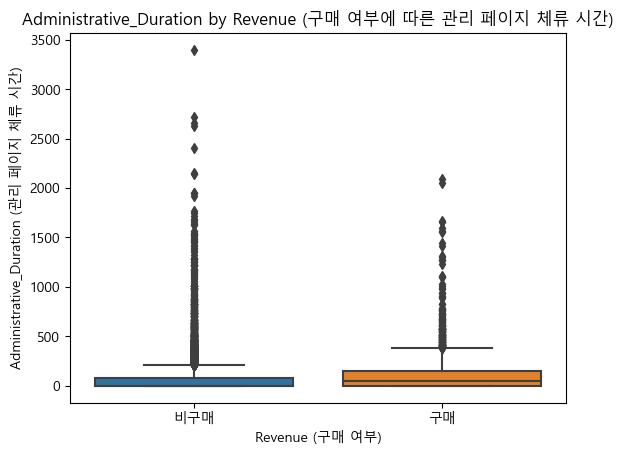

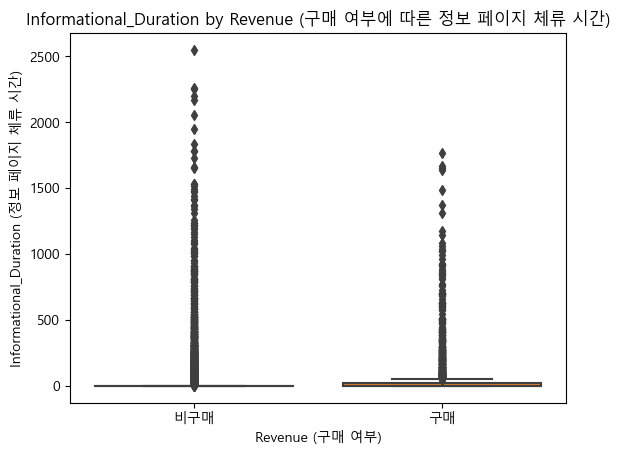

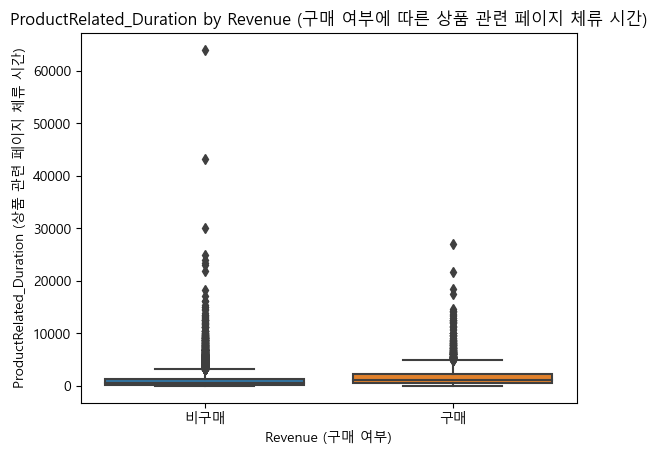

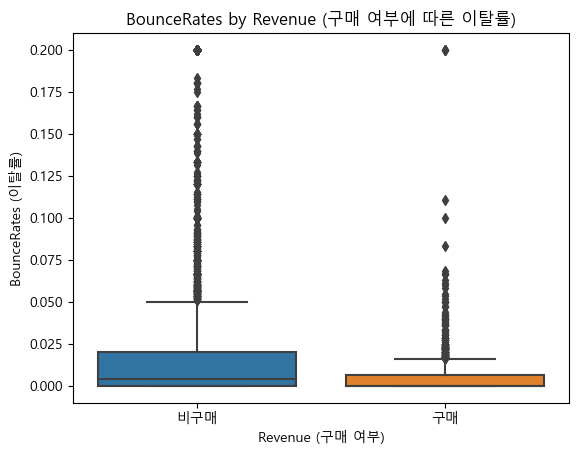

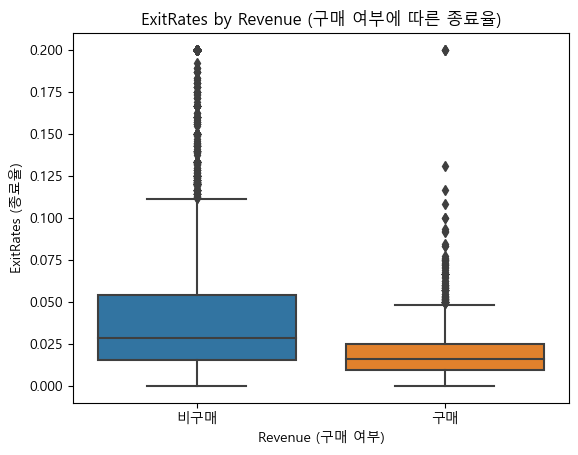

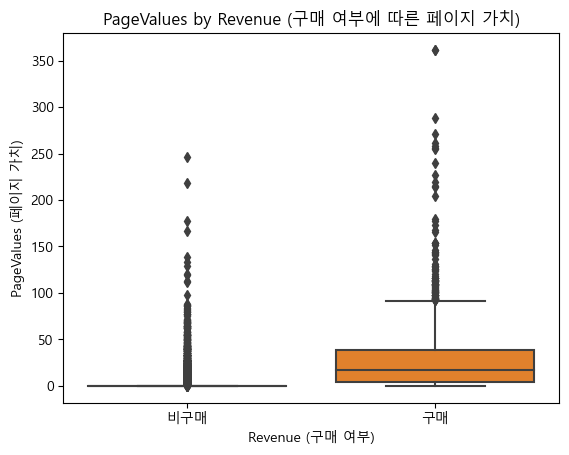

,Administrative_Duration,Informational_Duration,ProductRelated_Duration,BounceRates,ExitRates,PageValues
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,80.818611,34.472398,1194.746220,0.022191,0.043073,5.889258
std,176.779107,140.749294,1913.669288,0.048488,0.048597,18.568437
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,184.137500,0.000000,0.014286,0.000000
50%,7.500000,0.000000,598.936905,0.003112,0.025156,0.000000
75%,93.256250,0.000000,1464.157214,0.016813,0.050000,0.000000
max,3398.750000,2549.375000,63973.522230,0.200000,0.200000,361.763742


BounceRates가 0.2인 데이터의 Revenue (구매 여부):
False    697
True       3
Name: Revenue, dtype: int64
ExitRates가 0.2인 데이터의 Revenue (구매 여부):
False    707
True       3
Name: Revenue, dtype: int64
BounceRates와 ExitRates가 모두 0.2인 데이터의 Revenue (구매 여부):
False    697
True       3
Name: Revenue, dtype: int64
PageValues가 0인데 구매가 발생한 데이터 수:
370


In [18]:
#1. Administrative_Duration (관리 페이지 체류 시간)
sns.boxplot(data=df, x='Revenue', y='Administrative_Duration')

plt.title('Administrative_Duration by Revenue (구매 여부에 따른 관리 페이지 체류 시간)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('Administrative_Duration (관리 페이지 체류 시간)')
plt.xticks([0, 1], ['비구매', '구매'])
plt.show()

#2. Informational_Duration (정보 페이지 체류 시간)
sns.boxplot(data=df , x='Revenue', y='Informational_Duration')
plt.title('Informational_Duration by Revenue (구매 여부에 따른 정보 페이지 체류 시간)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('Informational_Duration (정보 페이지 체류 시간)')
plt.xticks([0, 1], ['비구매', '구매'])
plt.show()

#3. ProductRelated_Duration (상품 관련 페이지 체류 시간)
sns.boxplot(data=df, x='Revenue', y='ProductRelated_Duration')

plt.title('ProductRelated_Duration by Revenue (구매 여부에 따른 상품 관련 페이지 체류 시간)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('ProductRelated_Duration (상품 관련 페이지 체류 시간)')
plt.xticks([0, 1], ['비구매', '구매'])
plt.show()

#4. BounceRates (이탈률)
sns.boxplot(data=df, x='Revenue', y='BounceRates')

plt.title('BounceRates by Revenue (구매 여부에 따른 이탈률)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('BounceRates (이탈률)')
plt.xticks([0, 1], ['비구매', '구매'])
plt.show()

#5. ExitRates (종료율)
sns.boxplot(data=df, x='Revenue', y='ExitRates')

plt.title('ExitRates by Revenue (구매 여부에 따른 종료율)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('ExitRates (종료율)')
plt.xticks([0, 1], ['비구매', '구매'])
plt.show()

#6. PageValues (페이지 가치)
sns.boxplot(data=df, x='Revenue', y='PageValues')

plt.title('PageValues by Revenue (구매 여부에 따른 페이지 가치)')
plt.xlabel('Revenue (구매 여부)')
plt.ylabel('PageValues (페이지 가치)')
plt.xticks([0, 1], ['비구매', '구매'])
plt.show()

#Feature의 최대값, 중앙값, 평균 등을 확인작업
outlier_features = [
    'Administrative_Duration',
    'Informational_Duration',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues'
]

display(df[outlier_features].describe())

print('BounceRates가 0.2인 데이터의 Revenue (구매 여부):')
print(df[df['BounceRates'] == 0.2]['Revenue'].value_counts())

print('ExitRates가 0.2인 데이터의 Revenue (구매 여부):')
print(df[df['ExitRates'] == 0.2]['Revenue'].value_counts())

print('BounceRates와 ExitRates가 모두 0.2인 데이터의 Revenue (구매 여부):')
print(df[(df['BounceRates'] == 0.2) &
         (df['ExitRates'] == 0.2)]['Revenue'].value_counts())

print('PageValues가 0인데 구매가 발생한 데이터 수:')
print(df[(df['PageValues'] == 0) &
         (df['Revenue'] == True)].shape[0])


## 이상치 확인 결과
- 이상해 보였던 Feature (변수): Administrative_Duration (관리 페이지 체류 시간), Informational_Duration (정보 페이지 체류 시간), ProductRelated_Duration (상품 관련 페이지 체류 시간), BounceRates (이탈률), ExitRates (종료율), PageValues (페이지 가치)

- 어떤 값이었는가?: 체류 시간 관련 Feature (변수)에서는 매우 큰 값들이 있었고, BounceRates (이탈률)와 ExitRates (종료율)에서는 0.2가 눈에 띄었다.

- Revenue (구매 여부)와의 관계: BounceRates (이탈률)와 ExitRates (종료율)가 모두 0.2인 700개 중 697개가 비구매였다. PageValues (페이지 가치)가 0인데 구매한 데이터도 370개 있었다.

- 제거하고 싶은 값: 현재는 바로 제거하지 않고, BounceRates (이탈률)와 ExitRates (종료율)가 모두 0.2인 데이터는 조금 더 확인하고 싶다.

- 그대로 두고 싶은 값: 체류 시간 관련 Feature (변수)와 PageValues (페이지 가치)의 큰 값들은 우선 건드리지말고 그대로 두고 실행하면 좋을거 같다 

- 그렇게 판단한 이유: 이상치처럼 보여도 실제 고객 행동일 수 있고, 제거하면 Revenue (구매 여부)와 관련된 정보를 잃을 수 있기 때문에 판단 하였다.

# 19. DAY 3에서 내가 발견한 것 정리

## 구매 여부와 가장 관련 있어 보였던 Feature
1. PageValues (페이지 가치)
2. ProductRelated_Duration (상품 관련 페이지 체류 시간)
3. ProductRelated (상품 관련 페이지 방문 횟수)

### 예상과 비슷했던 결과
- 상품 관련 페이지를 많이 보고 오래 머문 경우에 Revenue (구매 여부)가 True인 경우가 더 많았고, BounceRates (이탈률)와 ExitRates (종료율)는 구매한 경우 더 낮게 나타났다.

### 예상과 달랐던 결과
- Returning Visitor (재방문자)가 구매 비율이 더 높을 것이라고 생각했지만, New Visitor (신규 방문자)의 구매 비율이 약 24.91%로 더 높게 나타났다.
- Month (방문 월)에서는 방문량이 가장 많았던 5월보다 11월의 구매 비율이 더 높게 나타났다.

### 전처리가 필요해 보이는 Feature
- Month (방문 월), OperatingSystems (운영체제), Browser (브라우저), Region (지역), TrafficType (유입 경로 유형), VisitorType (방문자 유형)과 이상치가 확인된 수치형 Feature (변수)들을 전처리할 때 확인할 필요가 있어 보인다.

### Encoding (범주형 데이터 변환)이 필요해 보이는 Feature
- Month (방문 월), OperatingSystems (운영체제), Browser (브라우저), Region (지역), TrafficType (유입 경로 유형), VisitorType (방문자 유형)

### Scaling (데이터 크기 조정)이 필요해 보이는 Feature
- Administrative (관리 페이지 방문 횟수), Administrative_Duration (관리 페이지 체류 시간), Informational (정보 페이지 방문 횟수), Informational_Duration (정보 페이지 체류 시간), ProductRelated (상품 관련 페이지 방문 횟수), ProductRelated_Duration (상품 관련 페이지 체류 시간), BounceRates (이탈률), ExitRates (종료율), PageValues (페이지 가치), SpecialDay (특별한 날과의 근접도)

### 이상치를 어떻게 처리하고 싶은가?
- 이상치라고 바로 제거하지 않고 실제 고객 행동일 가능성을 먼저 확인하고 싶다. 특히 BounceRates (이탈률)와 ExitRates (종료율)가 모두 0.2 인 데이터는 특이한 패턴을 보여 전처리할 때 다시 확인하고 싶다는 생각이 들었다.

### 새롭게 만들어보고 싶은 Feature
- 전체 페이지 방문 횟수: Administrative(관리 페이지 방문 횟수) + Informational (정보 페이지 방문 횟수) + ProductRelated(상품 관련 페이지 방문 횟수)
- 전체 페이지 체류 시간: Administrative_Duration(관리 페이지 체류 시간) + Informational_Duration(정보 페이지 체류 시간) + ProductRelated_Duration(상품 관련 페이지 체류 시간)

### DAY 4에서 가장 먼저 확인 해봐야하는 것
- Baseline 모델을 학습을 시킨뒤에 Accuracy(정확성)뿐만 아니라 ROC-AUC, Recall, F1-score 를 확인해서
  현재 데이터의 클래스 불균형 상황에서 모델이 구매 여부(Revenue)를 얼마나 잘 예측하는지 확인 해보는것이 목표이다.

# DAY 4. 데이터 전처리 · Baseline 모델링

## 오늘의 목표
- Feature / Target 구성
- Encoding
- Train / Test Split
- Scaling
- Baseline 설정
- 여러 Classification 모델 학습
- 평가 지표 비교
- Confusion Matrix 확인
- 현재 성능이 가장 좋은 후보 모델 확인

# 20. 전처리 전 데이터 다시 확인하기

In [19]:
 # 데이터 크기와 컬럼 확인
print('데이터 크기:', df.shape)
print('컬럼:')
print(df.columns)

# 결측치 확인
print('\n결측치:')
print(df.isnull().sum())

# 데이터 타입 확인
print('\n데이터 타입:')
print(df.dtypes)

# Target Revenue 분포 확인
print('\nRevenue 개수:')
print(df['Revenue'].value_counts())

print('\nRevenue 비율(%):')
print(df['Revenue'].value_counts(normalize=True) * 100)

데이터 크기: (12330, 18)
컬럼:
Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')

결측치:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

데이터 타입:
Administrative               int64
Administrative_Duration    float64
Informa

# 21. Feature / Target 구성하기

예측에 사용할 Feature와 Target을 분리한다.

### Target
- Revenue (구매 여부)

In [20]:
# Feature(X)와 Target(y) 분리
X = df.drop('Revenue', axis=1)
y = df['Revenue']

# X, y 크기 확인
print('X 크기:', X.shape)
print('y 크기:', y.shape)

# Revenue가 X에 포함되어 있는지 확인
print('Revenue가 X에 포함되어 있는가?:', 'Revenue' in X.columns)

# Feature 확인
print('\nFeature 목록:')
print(X.columns)

# Target 분포 확인
print('\nTarget 분포:')
print(y.value_counts())

X 크기: (12330, 17)
y 크기: (12330,)
Revenue가 X에 포함되어 있는가?: False

Feature 목록:
Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend'],
      dtype='object')

Target 분포:
False    10422
True      1908
Name: Revenue, dtype: int64


# 22. Encoding 적용하기

범주형 Feature를 모델이 사용할 수 있는 형태로 변환한다.

### Day 3에서 확인한 Encoding 대상
- Month (방문 월)
- OperatingSystems (운영체제)
- Browser (브라우저)
- Region (지역)
- TrafficType (유입 경로 유형)
- VisitorType (방문자 유형)

In [21]:
# encoding 대상 Feature 확인 
encoding_features = [
    'Month',
    'OperatingSystems',
    'Browser',
    'Region',
    'TrafficType',
    'VisitorType'
]
# one-hot encoding 수행 해볼 예정 
X_encoded = pd.get_dummies(
    X,
    columns=encoding_features,
    drop_first=True
)

display(X_encoded)
#Encoding 후 확인
print('Encoding 전 X 크기:', X.shape)
print('Encoding 후 X 크기:', X_encoded.shape)

print('\nEncoding 후 컬럼:')
print(X_encoded.columns)

 



,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,TrafficType_13,TrafficType_14,TrafficType_15,TrafficType_16,TrafficType_17,TrafficType_18,TrafficType_19,TrafficType_20,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,0,0,0,0,0,0,0,0,0,1
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,...,0,0,0,0,0,0,0,0,0,1
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,0,0,0,0,0,0,0,0,0,1
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,...,0,0,0,0,0,0,0,0,0,1
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,...,0,0,0,0,0,0,0,0,0,1
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,...,0,0,0,0,0,0,0,0,0,1
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,...,1,0,0,0,0,0,0,0,0,1
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,...,0,0,0,0,0,0,0,0,0,1


Encoding 전 X 크기: (12330, 17)
Encoding 후 X 크기: (12330, 68)

Encoding 후 컬럼:
Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend',
       'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar',
       'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep',
       'OperatingSystems_2', 'OperatingSystems_3', 'OperatingSystems_4',
       'OperatingSystems_5', 'OperatingSystems_6', 'OperatingSystems_7',
       'OperatingSystems_8', 'Browser_2', 'Browser_3', 'Browser_4',
       'Browser_5', 'Browser_6', 'Browser_7', 'Browser_8', 'Browser_9',
       'Browser_10', 'Browser_11', 'Browser_12', 'Browser_13', 'Region_2',
       'Region_3', 'Region_4', 'Region_5', 'Region_6', 'Region_7', 'Region_8',
       'Region_9', 'TrafficType_2', 'TrafficType_3', 'TrafficType_4',
       'TrafficType_5', 'TrafficType_6', 'TrafficType_7', 'Traf

# 23. Train / Test Split

모델 학습용 데이터와 최종 평가용 데이터를 분리한다.

In [22]:
from sklearn.model_selection import train_test_split

# Train / Test 데이터 분리  Test_size=0.2 로잡고 Random_state=42로 설정하고 stratify=y로 설정해서 데이터를 균형있게 분리하는 작업을 수행해봄 
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train / Test 데이터가 잘 분리 되었는지 확인하는 작업 
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((9864, 68), (2466, 68), (9864,), (2466,))

# 24. Scaling 적용하기

필요한 수치형 Feature에 Scaling을 적용한다.

### Day 3에서 확인한 Scaling 후보
- Administrative (관리 목적 페이지 방문 횟수)
- Administrative_Duration (관리 목적 페이지 체류 시간)
- Informational (정보 제공 페이지 방문 횟수)
- Informational_Duration (정보 제공 페이지 체류 시간)
- ProductRelated (상품 관련 페이지 방문 횟수)
- ProductRelated_Duration (상품 관련 페이지 체류 시간)
- BounceRates (이탈률)
- ExitRates (종료율)
- PageValues (구매 과정에서의 페이지 가치)
- SpecialDay (특정 기념일과의 근접도)

In [23]:
from sklearn.preprocessing import StandardScaler

# Scaling할 수치형 Feature 확인
scaling_features = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

# 원본 Train / Test를 복사하고 진행 원본 데이터에다가 수정이 되지 않도록 복사본을 만들어서 진행해야한다,
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# StandardScaler 생성
scaler = StandardScaler()

# Train 데이터로만 학습하고 스케일링을 한다
X_train_scaled[scaling_features] = scaler.fit_transform(
    X_train[scaling_features]
)

# Test 데이터는 Train에서 학습한 scaler로 스케일링만 수행
X_test_scaled[scaling_features] = scaler.transform(
    X_test[scaling_features]
)

# 위에서 스케일링이 잘되어있는지 확인 해보는 작업 
X_train_scaled[scaling_features]


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
4263,1.712088,3.624745,-0.395782,-0.244589,0.058405,0.083393,-0.353793,-0.612923,0.341014,3.663440
5905,-0.698294,-0.452341,-0.395782,-0.244589,-0.629459,-0.539163,0.360698,1.159262,-0.320268,-0.311499
9434,-0.698294,-0.452341,-0.395782,-0.244589,-0.629459,-0.599504,-0.458865,0.136746,-0.320268,-0.311499
3505,-0.095698,1.429605,-0.395782,-0.244589,-0.331385,0.009963,-0.202751,-0.118883,0.716100,3.663440
2067,-0.698294,-0.452341,-0.395782,-0.244589,0.012548,-0.187989,-0.458865,-0.873776,2.625461,-0.311499
...,...,...,...,...,...,...,...,...,...,...
2419,0.506897,-0.068157,0.388468,-0.244589,-0.285527,-0.317442,-0.243190,0.118807,0.882743,-0.311499
1200,0.506897,-0.359543,-0.395782,-0.244589,0.837985,0.737078,-0.398603,-0.623124,-0.320268,-0.311499
2398,-0.698294,-0.452341,-0.395782,-0.244589,-0.331385,-0.394631,0.023231,0.176844,-0.320268,4.657175
11106,-0.698294,-0.452341,-0.395782,-0.244589,0.952629,0.837152,-0.402730,-0.572522,0.010313,-0.311499


# 25. Baseline 모델 만들기

가장 단순한 모델의 성능을 기준점으로 확인한다.

### Baseline 후보
- Dummy Classifier
- Logistic Regression

### 기록할 평가 지표
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

In [24]:
# 필요한 라이브러리 불러오기
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Dummy Classifier 모델 생성
dummy = DummyClassifier(strategy='most_frequent', random_state=42)

# 모델 학습
dummy.fit(X_train, y_train)

# 예측
y_pred_dummy = dummy.predict(X_test)
y_proba_dummy = dummy.predict_proba(X_test)[:, 1]

# Logistic Regression 모델 생성
logistic = LogisticRegression(max_iter=1000, random_state=42)

# 모델 학습
logistic.fit(X_train_scaled, y_train)

# 예측
y_pred_logistic = logistic.predict(X_test_scaled)
y_proba_logistic = logistic.predict_proba(X_test_scaled)[:, 1]

# Dummy Classifier 성능 확인
print('Dummy Classifier')
print('Accuracy:', round(accuracy_score(y_test, y_pred_dummy), 4))
print('Precision:', round(precision_score(y_test, y_pred_dummy, zero_division=0), 4))
print('Recall:', round(recall_score(y_test, y_pred_dummy, zero_division=0), 4))
print('F1-score:', round(f1_score(y_test, y_pred_dummy, zero_division=0), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba_dummy), 4))

# Logistic Regression 성능 확인
print('\nLogistic Regression')
print('Accuracy:', round(accuracy_score(y_test, y_pred_logistic), 4))
print('Precision:', round(precision_score(y_test, y_pred_logistic), 4))
print('Recall:', round(recall_score(y_test, y_pred_logistic), 4))
print('F1-score:', round(f1_score(y_test, y_pred_logistic), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba_logistic), 4))

Dummy Classifier
Accuracy: 0.8451
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.5

Logistic Regression
Accuracy: 0.8816
Precision: 0.7419
Recall: 0.3613
F1-score: 0.4859
ROC-AUC: 0.8835


### 결과
- Dummy Classifier는 Accuracy가 0.8451이지만 구매자를 예측하지 못해 Recall과 F1-score가 0으로 나타났다.
- Logistic Regression은 Accuracy 0.8816, ROC-AUC 0.8835로 Dummy Classifier보다 좋은 성능을 보였다.
- 다만 Recall은 0.3613으로 실제 구매자를 놓치는 경우가 많은 것으로 나타났다.

# 26. Logistic Regression 학습 및 평가

Logistic Regression 모델을 학습하고 주요 Classification Metric을 확인한다.

Logistic Regression (로지스틱 회귀)
Accuracy (정확도): 0.8816
Precision (정밀도): 0.7419
Recall (재현율): 0.3613
F1-score (F1 점수): 0.4859
ROC-AUC (분류 성능): 0.8835


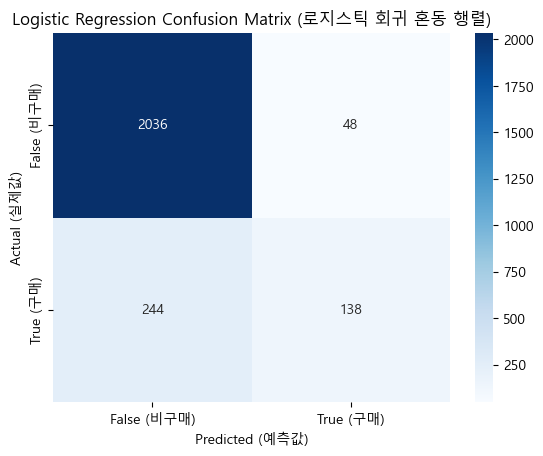

In [25]:
# 필요한 라이브러리 불러오기
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Logistic Regression 평가 지표 계산
log_accuracy = accuracy_score(y_test, y_pred_logistic)
log_precision = precision_score(y_test, y_pred_logistic)
log_recall = recall_score(y_test, y_pred_logistic)
log_f1 = f1_score(y_test, y_pred_logistic)
log_roc_auc = roc_auc_score(y_test, y_proba_logistic)

# Confusion Matrix 계산
log_cm = confusion_matrix(y_test, y_pred_logistic)

# 결과 확인
print('Logistic Regression (로지스틱 회귀)')
print('Accuracy (정확도):', round(log_accuracy, 4))
print('Precision (정밀도):', round(log_precision, 4))
print('Recall (재현율):', round(log_recall, 4))
print('F1-score (F1 점수):', round(log_f1, 4))
print('ROC-AUC (분류 성능):', round(log_roc_auc, 4))

# Confusion Matrix 시각화
sns.heatmap(
    log_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['False (비구매)', 'True (구매)'],
    yticklabels=['False (비구매)', 'True (구매)']
)

plt.xlabel('Predicted (예측값)')
plt.ylabel('Actual (실제값)')
plt.title('Logistic Regression Confusion Matrix (로지스틱 회귀 혼동 행렬)')
plt.show()

# 27. Decision Tree 학습 및 평가

Decision Tree 모델을 학습하고 Baseline과 성능을 비교한다.

Decision Tree (의사결정나무)
Accuracy (정확도): 0.8601
Precision (정밀도): 0.5486
Recall (재현율): 0.5471
F1-score (F1 점수): 0.5478
ROC-AUC (분류 성능): 0.7323


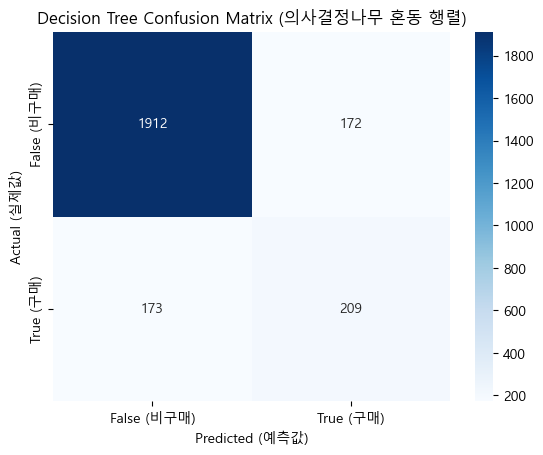

In [26]:
# 필요한 라이브러리 불러오기
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Decision Tree 모델 생성
dt = DecisionTreeClassifier(random_state=42)

# 모델 학습
dt.fit(X_train, y_train)

# 예측
y_pred_dt = dt.predict(X_test)
y_proba_dt = dt.predict_proba(X_test)[:, 1]

# 평가 지표 계산
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)
dt_roc_auc = roc_auc_score(y_test, y_proba_dt)

# Confusion Matrix 계산
dt_cm = confusion_matrix(y_test, y_pred_dt)

# 결과 확인
print('Decision Tree (의사결정나무)')
print('Accuracy (정확도):', round(dt_accuracy, 4))
print('Precision (정밀도):', round(dt_precision, 4))
print('Recall (재현율):', round(dt_recall, 4))
print('F1-score (F1 점수):', round(dt_f1, 4))
print('ROC-AUC (분류 성능):', round(dt_roc_auc, 4))

# Confusion Matrix 시각화
sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['False (비구매)', 'True (구매)'],
    yticklabels=['False (비구매)', 'True (구매)']
)

plt.xlabel('Predicted (예측값)')
plt.ylabel('Actual (실제값)')
plt.title('Decision Tree Confusion Matrix (의사결정나무 혼동 행렬)')
plt.show()

# 28. Random Forest 학습 및 평가

Random Forest 모델을 학습하고 앞의 모델들과 성능을 비교한다.

Random Forest (랜덤 포레스트)
Accuracy (정확도): 0.899
Precision (정밀도): 0.7548
Recall (재현율): 0.5157
F1-score (F1 점수): 0.6128
ROC-AUC (분류 성능): 0.9153


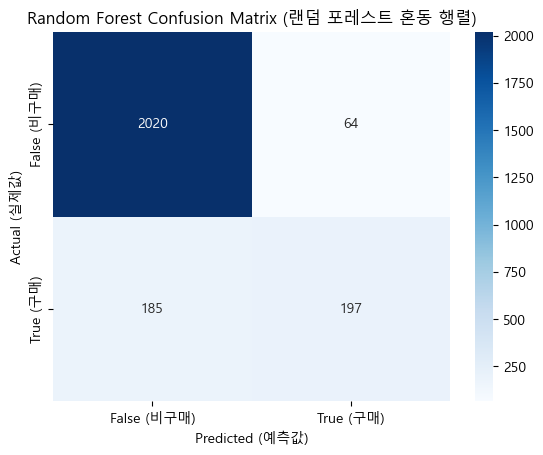

In [27]:
# 필요한 라이브러리 불러오기
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Random Forest 모델 생성
rf = RandomForestClassifier(random_state=42)

# 모델 학습
rf.fit(X_train, y_train)

# 예측
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

# 평가 지표 계산
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_proba_rf)

# Confusion Matrix 계산
rf_cm = confusion_matrix(y_test, y_pred_rf)

# 결과 확인
print('Random Forest (랜덤 포레스트)')
print('Accuracy (정확도):', round(rf_accuracy, 4))
print('Precision (정밀도):', round(rf_precision, 4))
print('Recall (재현율):', round(rf_recall, 4))
print('F1-score (F1 점수):', round(rf_f1, 4))
print('ROC-AUC (분류 성능):', round(rf_roc_auc, 4))

# Confusion Matrix 시각화
sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['False (비구매)', 'True (구매)'],
    yticklabels=['False (비구매)', 'True (구매)']
)

plt.xlabel('Predicted (예측값)')
plt.ylabel('Actual (실제값)')
plt.title('Random Forest Confusion Matrix (랜덤 포레스트 혼동 행렬)')
plt.show()

# 29. Gradient Boosting 학습 및 평가

Gradient Boosting 모델을 학습하고 앞의 모델들과 성능을 비교한다.

Gradient Boosting (그래디언트 부스팅)
Accuracy (정확도): 0.9019
Precision (정밀도): 0.7215
Recall (재현율): 0.5969
F1-score (F1 점수): 0.6533
ROC-AUC (분류 성능): 0.9285


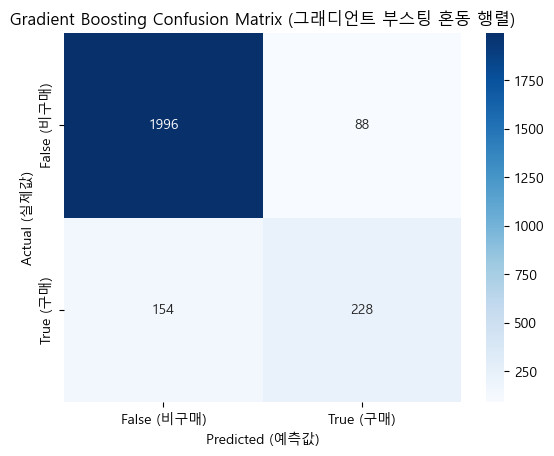

In [28]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

#모델 생성 
gb = GradientBoostingClassifier(random_state=42)

#모델 학습 
gb.fit(X_train,y_train)

#예측 
y_pred_gb = gb.predict(X_test)
y_proba_gb = gb.predict_proba(X_test)[:,1]

#평가 지표 계산
gb_accuracy = accuracy_score(y_test,y_pred_gb)
gb_precision = precision_score(y_test,y_pred_gb)
gb_recall = recall_score(y_test,y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)
gb_roc_auc = roc_auc_score(y_test, y_proba_gb)

#Confusion Matrix 계산 
gb_cm = confusion_matrix(y_test, y_pred_gb)

# 결과 확인
print('Gradient Boosting (그래디언트 부스팅)')
print('Accuracy (정확도):', round(gb_accuracy, 4))
print('Precision (정밀도):', round(gb_precision, 4))
print('Recall (재현율):', round(gb_recall, 4))
print('F1-score (F1 점수):', round(gb_f1, 4))
print('ROC-AUC (분류 성능):', round(gb_roc_auc, 4))

# Confusion Matrix 시각화
sns.heatmap(
    gb_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['False (비구매)', 'True (구매)'],
    yticklabels=['False (비구매)', 'True (구매)']
)

plt.xlabel('Predicted (예측값)')
plt.ylabel('Actual (실제값)')
plt.title('Gradient Boosting Confusion Matrix (그래디언트 부스팅 혼동 행렬)')
plt.show()



# 30. Keras MLP 학습 및 평가

Keras MLP 모델을 학습하고 다른 Classification 모델과 성능을 비교한다.

Epoch 1/20
247/247 [==============================] - 2s 3ms/step - loss: 0.3372 - accuracy: 0.8546 - val_loss: 0.2653 - val_accuracy: 0.8971
Epoch 2/20
247/247 [==============================] - 0s 2ms/step - loss: 0.2517 - accuracy: 0.8939 - val_loss: 0.2543 - val_accuracy: 0.8946
Epoch 3/20
247/247 [==============================] - 0s 2ms/step - loss: 0.2371 - accuracy: 0.9004 - val_loss: 0.2478 - val_accuracy: 0.8966
Epoch 4/20
247/247 [==============================] - 0s 2ms/step - loss: 0.2291 - accuracy: 0.9041 - val_loss: 0.2434 - val_accuracy: 0.9042
Epoch 5/20
247/247 [==============================] - 0s 2ms/step - loss: 0.2230 - accuracy: 0.9063 - val_loss: 0.2387 - val_accuracy: 0.9052
Epoch 6/20
247/247 [==============================] - 0s 2ms/step - loss: 0.2172 - accuracy: 0.9081 - val_loss: 0.2411 - val_accuracy: 0.9042
Epoch 7/20
247/247 [==============================] - 0s 2ms/step - loss: 0.2125 - accuracy: 0.9099 - val_loss: 0.2444 - val_accuracy: 0.8966
Epoch 

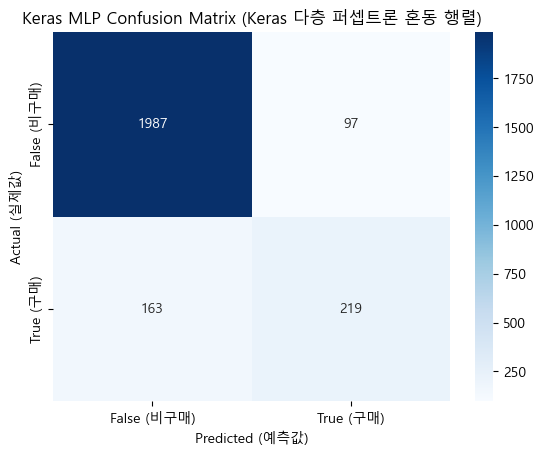

In [29]:
# 필요한 라이브러리 불러오기
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 재현성을 위한 시드 설정
tf.random.set_seed(42)

# Keras MLP 모델 생성
mlp = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 모델 컴파일
mlp.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 모델 학습
history = mlp.fit(
    X_train_scaled.astype('float32'),
    y_train.astype('float32'),
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 구매 확률 예측
y_proba_mlp = mlp.predict(
    X_test_scaled.astype('float32')
).ravel()

# 0.5 기준으로 구매 여부 예측
y_pred_mlp = (y_proba_mlp >= 0.5).astype(int)

# 평가 지표 계산
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
mlp_precision = precision_score(y_test, y_pred_mlp)
mlp_recall = recall_score(y_test, y_pred_mlp)
mlp_f1 = f1_score(y_test, y_pred_mlp)
mlp_roc_auc = roc_auc_score(y_test, y_proba_mlp)

# Confusion Matrix 계산
mlp_cm = confusion_matrix(y_test, y_pred_mlp)

# 결과 확인
print('Keras MLP (다층 퍼셉트론)')
print('Accuracy (정확도):', round(mlp_accuracy, 4))
print('Precision (정밀도):', round(mlp_precision, 4))
print('Recall (재현율):', round(mlp_recall, 4))
print('F1-score (F1 점수):', round(mlp_f1, 4))
print('ROC-AUC (분류 성능):', round(mlp_roc_auc, 4))


# Confusion Matrix 시각화
sns.heatmap(
    mlp_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['False (비구매)', 'True (구매)'],
    yticklabels=['False (비구매)', 'True (구매)']
)

plt.xlabel('Predicted (예측값)')
plt.ylabel('Actual (실제값)')
plt.title('Keras MLP Confusion Matrix (Keras 다층 퍼셉트론 혼동 행렬)')
plt.show()

# 31. 모델별 성능 비교

학습한 모델의 주요 평가 지표를 한눈에 비교한다.

In [30]:
# 모델별 성능 비교
model_results = pd.DataFrame({
    'Model (모델)': [
        'Dummy Classifier (더미 분류기)',
        'Logistic Regression (로지스틱 회귀)',
        'Decision Tree (의사결정나무)',
        'Random Forest (랜덤 포레스트)',
        'Gradient Boosting (그래디언트 부스팅)',
        'Keras MLP (다층 퍼셉트론)'
    ],
    
    'Accuracy (정확도)': [
        accuracy_score(y_test, y_pred_dummy),
        log_accuracy,
        dt_accuracy,
        rf_accuracy,
        gb_accuracy,
        mlp_accuracy
    ],
    
    'Precision (정밀도)': [
        precision_score(y_test, y_pred_dummy, zero_division=0),
        log_precision,
        dt_precision,
        rf_precision,
        gb_precision,
        mlp_precision
    ],
    
    'Recall (재현율)': [
        recall_score(y_test, y_pred_dummy, zero_division=0),
        log_recall,
        dt_recall,
        rf_recall,
        gb_recall,
        mlp_recall
    ],
    
    'F1-score (F1 점수)': [
        f1_score(y_test, y_pred_dummy, zero_division=0),
        log_f1,
        dt_f1,
        rf_f1,
        gb_f1,
        mlp_f1
    ],
    
    'ROC-AUC (분류 성능)': [
        roc_auc_score(y_test, y_proba_dummy),
        log_roc_auc,
        dt_roc_auc,
        rf_roc_auc,
        gb_roc_auc,
        mlp_roc_auc
    ]
})

# 결과 확인
model_results.round(4)

,Model (모델),Accuracy (정확도),Precision (정밀도),Recall (재현율),F1-score (F1 점수),ROC-AUC (분류 성능)
0,Dummy Classifier (더미 분류기),0.8451,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression (로지스틱 회귀),0.8816,0.7419,0.3613,0.4859,0.8835
2,Decision Tree (의사결정나무),0.8601,0.5486,0.5471,0.5478,0.7323
3,Random Forest (랜덤 포레스트),0.8990,0.7548,0.5157,0.6128,0.9153
4,Gradient Boosting (그래디언트 부스팅),0.9019,0.7215,0.5969,0.6533,0.9285
5,Keras MLP (다층 퍼셉트론),0.8946,0.6930,0.5733,0.6275,0.9101


# 32. Confusion Matrix 비교

각 모델의 Confusion Matrix를 확인한다.

<Figure size 1400x700 with 0 Axes>

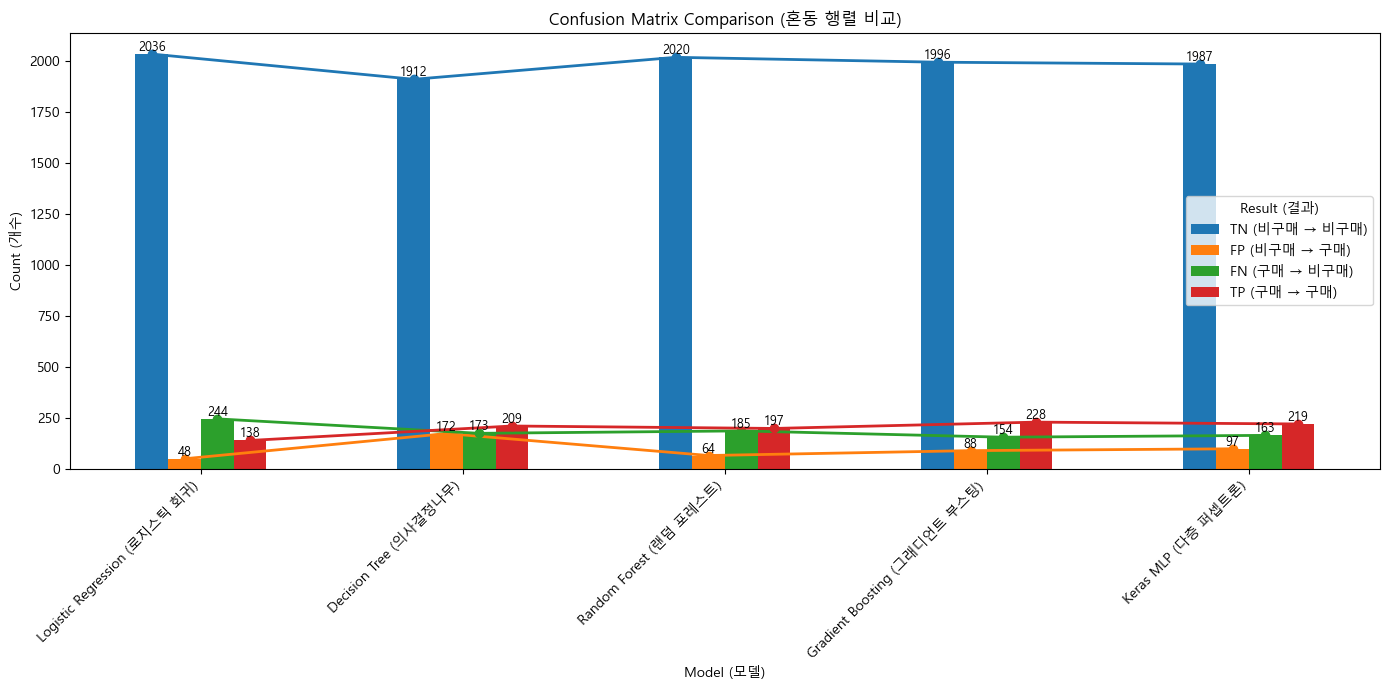

,Model (모델),TN (비구매 → 비구매),FP (비구매 → 구매),FN (구매 → 비구매),TP (구매 → 구매)
0,Logistic Regression (로지스틱 회귀),2036,48,244,138
1,Decision Tree (의사결정나무),1912,172,173,209
2,Random Forest (랜덤 포레스트),2020,64,185,197
3,Gradient Boosting (그래디언트 부스팅),1996,88,154,228
4,Keras MLP (다층 퍼셉트론),1987,97,163,219


In [31]:
# 각 모델의 Confusion Matrix 값 추출
log_tn, log_fp, log_fn, log_tp = log_cm.ravel()
dt_tn, dt_fp, dt_fn, dt_tp = dt_cm.ravel()
rf_tn, rf_fp, rf_fn, rf_tp = rf_cm.ravel()
gb_tn, gb_fp, gb_fn, gb_tp = gb_cm.ravel()
mlp_tn, mlp_fp, mlp_fn, mlp_tp = mlp_cm.ravel()

# Confusion Matrix 비교표 생성
cm_results = pd.DataFrame({
    'Model (모델)': [
        'Logistic Regression (로지스틱 회귀)',
        'Decision Tree (의사결정나무)',
        'Random Forest (랜덤 포레스트)',
        'Gradient Boosting (그래디언트 부스팅)',
        'Keras MLP (다층 퍼셉트론)'
    ],
    'TN (비구매 → 비구매)': [
        log_tn, dt_tn, rf_tn, gb_tn, mlp_tn
    ],
    'FP (비구매 → 구매)': [
        log_fp, dt_fp, rf_fp, gb_fp, mlp_fp
    ],
    'FN (구매 → 비구매)': [
        log_fn, dt_fn, rf_fn, gb_fn, mlp_fn
    ],
    'TP (구매 → 구매)': [
        log_tp, dt_tp, rf_tp, gb_tp, mlp_tp
    ]
})

# Confusion Matrix 비교 그래프
plt.figure(figsize=(14, 7))

# 비교할 항목
columns = [
    'TN (비구매 → 비구매)',
    'FP (비구매 → 구매)',
    'FN (구매 → 비구매)',
    'TP (구매 → 구매)'
]

# 막대그래프
ax = cm_results.plot(
    x='Model (모델)',
    y=columns,
    kind='bar',
    figsize=(14, 7)
)

# 막대 위치에 점과 선 추가
for container, column in zip(ax.containers, columns):
    x = [bar.get_x() + bar.get_width() / 2 for bar in container]
    y = cm_results[column]

    ax.plot(
        x,
        y,
        marker='o',
        linewidth=2
    )

    # 점 위에 값 표시
    for x_pos, y_pos in zip(x, y):
        ax.text(
            x_pos,
            y_pos,
            str(y_pos),
            ha='center',
            va='bottom',
            fontsize=9

        )
plt.title('Confusion Matrix Comparison (혼동 행렬 비교)')
plt.xlabel('Model (모델)')
plt.ylabel('Count (개수)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Result (결과)')
plt.tight_layout()
plt.show()

# 결과 확인
cm_results

# 33. DAY 4 결과 정리

## 전처리 결과
- Revenue를 Target으로 분리하고 나머지 17개 변수를 Feature로 사용하였다.
- 범주형 변수는 One-Hot Encoding을 적용하였다.
- Train/Test 데이터를 8:2 비율로 분리하고 Target 비율을 유지하기 위해 stratify를 적용하였다.
- Logistic Regression과 Keras MLP에 사용할 수치형 Feature에는 StandardScaler를 적용하였다.

## Baseline 성능
- Dummy Classifier는 Accuracy 0.8451이었지만 Recall과 F1-score가 0으로 나타나 실제 구매자를 찾아내지 못하였다.
- Logistic Regression은 Accuracy 0.8816, ROC-AUC 0.8835로 Dummy Classifier보다 좋은 성능을 보였지만 Recall은 0.3613으로 실제 구매자를 놓치는 경우가 많았다.

## 모델별 성능 비교 결과
- Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, Keras MLP의 성능을 비교하였다.
- Gradient Boosting은 Accuracy 0.9019, Recall 0.5969, F1-score 0.6533, ROC-AUC 0.9285로 전반적으로 가장 좋은 성능을 보였다.
- Random Forest는 Precision 0.7548로 가장 높았지만, Recall과 F1-score에서는 Gradient Boosting이 더 높은 성능을 보였다.

## 현재 성능이 가장 좋은 후보 모델
- Gradient Boosting (그래디언트 부스팅)을 현재 가장 좋은 후보 모델로 선정하였다.
- Random Forest는 Precision에서 가장 좋은 성능을 보였지만, Accuracy, Recall, F1-score, ROC-AUC를 종합적으로 비교했을 때 Gradient Boosting이 더 좋은 성능을 보였다.
- 따라서 Day 5에서는 Gradient Boosting을 기준 모델로 사용하여 성능 개선 실험을 진행해보면 좋을거같다.

## Confusion Matrix에서 확인한 점
- Confusion Matrix를 통해 각 모델이 구매와 비구매를 올바르게 예측한 경우와 잘못 예측한 경우를 확인하였다.
- FN을 통해 실제 구매자를 비구매로 잘못 예측한 경우를 확인하였고, FP를 통해 실제 비구매자를 구매로 잘못 예측한 경우를 확인하였다.
- 구매 가능성이 있는 고객을 놓치지 않는 것이 중요하다고 판단하여 FN과 Recall을 중요하게 확인하였다.
- 다만 Recall만으로 모델을 평가하지 않고 Accuracy, F1-score, ROC-AUC도 함께 확인하여 전체적인 성능을 비교하였다.

# DAY 4 고찰

### 1. 어떤 전처리를 적용했고, 그 이유는 무엇인가?
- Revenue를 Target으로 분리하고 나머지 17개 변수를 Feature로 사용했다.
- 범주형 변수는 One-Hot Encoding을 적용하였다.
- Train/Test 데이터를 8:2 비율로 분리하고 Target 비율을 유지하기 위해 stratify를 적용하였다.
- Logistic Regression과 Keras MLP에 사용할 수치형 Feature에는 StandardScaler를 적용하였다.

### 2. Baseline 대비 성능이 가장 좋았던 모델은 무엇인가?
- Baseline인 Dummy Classifier와 비교했을 때 Gradient Boosting이 가장 좋은 성능을 보였다.
- Gradient Boosting은 Accuracy 0.9019, Recall 0.5969, F1-score 0.6533, ROC-AUC 0.9285로 전반적으로 높은 성능을 보였다.
- Random Forest도 Precision 0.7548로 가장 높았지만, 여러 평가 지표를 종합적으로 비교하여 Gradient Boosting을 가장 좋은 후보 모델로 선정하였다.

### 3. Accuracy와 F1-score / Recall / ROC-AUC 중 어떤 지표를 더 중요하게 봐야 한다고 생각하는가?
- 이번 데이터는 비구매 데이터가 구매 데이터보다 많기 때문에 Accuracy만으로 모델의 성능을 판단하기 어렵다고 생각하였다.
- 실제 구매 가능성이 있는 고객을 놓치지 않는 것이 중요하다고 생각하여 Recall을 중요하게 확인하였다.
- 또한 Precision과 Recall을 함께 고려하는 F1-score와 전체적인 분류 성능을 확인할 수 있는 ROC-AUC도 함께 확인하는 것이 중요하다고 생각하였다.

### 4. 모델별 성능 차이는 왜 발생했다고 생각하는가?
- 각 모델마다 데이터를 학습하고 분류하는 방법이 다르기 때문에 성능 차이가 발생했다고 생각한다.
- Logistic Regression은 비교적 단순한 방식으로 데이터를 분류하지만, Decision Tree, Random Forest, Gradient Boosting은 데이터의 복잡한 관계를 학습할 수 있다.
- 특히 Gradient Boosting은 여러 트리를 순차적으로 학습하면서 이전 모델의 오류를 보완하기 때문에 이번 데이터에서 좋은 성능을 보인 것이라고 생각한다.

### 5. 현재 모델에서 가장 먼저 개선해보고 싶은 부분은 무엇인가?
- 현재 가장 좋은 성능을 보인 Gradient Boosting도 Recall이 0.5969이기 때문에 실제 구매자를 놓치는 경우가 존재한다.
- 따라서 실제 구매자를 비구매로 잘못 예측하는 FN을 줄이고 Recall을 높이는 방향으로 개선해보고 싶다.
- 다음 단계에서는 새로운 Feature를 추가하거나 모델의 하이퍼파라미터 값을 변경하여 기존 모델과 성능을 비교해보면 좋을거 같다.
- 하이퍼파라미터 값을 직접 변경하면서 성능 변화를 확인하고, GridSearchCV를 활용하여 여러 설정값의 조합도 비교해보면 좋을거 같다.
- 이때 Recall뿐만 아니라 Accuracy, F1-score, ROC-AUC도 함께 확인하여 모델의 전체적인 성능을 비교해 보면 좋을거 같다.

# DAY 5. 모델 성능 개선

Gradient Boosting, Random Forest, XGBoost, DNN을 비교하고 전처리, 가중치, 파생변수 및 하이퍼파라미터를 조정한다.

## 34. Validation 데이터 나누기
Train 데이터를 학습용과 검증용으로 다시 나눈다. 최종 Test는 사용하지 않는다.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler

X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# 분류 성능을 같은 기준으로 비교
# predict()는 기본 분류 기준을 사용한다.
def evaluate_model(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_eval, pred).ravel()
    return {
        '실험': name,
        'Accuracy': accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred, zero_division=0),
        'Recall': recall_score(y_eval, pred, zero_division=0),
        'F1-score': f1_score(y_eval, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_eval, proba),
        'FN': fn,
        'FP': fp
    }

experiment_results = []
base_model = GradientBoostingClassifier(random_state=42)
base_model.fit(X_fit, y_fit)
base_result = evaluate_model('기존 Gradient Boosting', base_model, X_valid, y_valid)
experiment_results.append(base_result)

## 35. GB 컬럼 삭제 비교
기본 GB와 ProductRelated_Duration, BounceRates를 각각 또는 함께 삭제한 결과를 비교한다.

In [33]:
drop_cases = {
    'ProductRelated_Duration 삭제': ['ProductRelated_Duration'],
    'BounceRates 삭제': ['BounceRates'],
    '두 컬럼 모두 삭제': ['ProductRelated_Duration', 'BounceRates']
}
two_drop_cols = ['ProductRelated_Duration', 'BounceRates']
for name, cols in drop_cases.items():
    model = GradientBoostingClassifier(random_state=42)
    model.fit(X_fit.drop(columns=cols), y_fit)
    experiment_results.append(evaluate_model(
        name, model, X_valid.drop(columns=cols), y_valid
    ))

## 36. Logistic Regression Scaling 비교
StandardScaler와 MinMaxScaler 두 방법만 비교한다.

In [34]:
for scaler_name, scaler in [('StandardScaler', StandardScaler()), ('MinMaxScaler', MinMaxScaler())]:
    X_fit_scale = X_fit.copy()
    X_valid_scale = X_valid.copy()
    X_fit_scale[scaling_features] = scaler.fit_transform(X_fit[scaling_features])
    X_valid_scale[scaling_features] = scaler.transform(X_valid[scaling_features])
    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_fit_scale, y_fit)
    experiment_results.append(evaluate_model(
        scaler_name + ' + Logistic', model, X_valid_scale, y_valid
    ))

## 37. MLP / DNN 구조 5개 비교
기존에 배운 Sequential, Dense, Dropout, StandardScaler만 사용한다.

- 기본 MLP: 64 → 32 (Dropout 없음)
- 넓은 MLP: 128 → 64 (Dropout 없음)
- 깊은 DNN: 128 → 64 → 32 (Dropout 없음)
- 작은 DNN: 64 → 32 → 16 (Dropout 없음)
- DNN + Dropout: 128 → 64 → 32 (Dropout 0.2)

학습 조건은 모두 epochs=20, batch_size=32로 동일하게 두고 Validation 데이터에서 비교한다. 최종 Test 데이터는 사용하지 않는다.

In [35]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 신경망 입력값은 StandardScaler로 변환
mlp_scaler = StandardScaler()
X_fit_mlp = X_fit.copy()
X_valid_mlp = X_valid.copy()
X_fit_mlp[scaling_features] = mlp_scaler.fit_transform(X_fit[scaling_features])
X_valid_mlp[scaling_features] = mlp_scaler.transform(X_valid[scaling_features])

# 은닉층의 뉴런 수와 Dropout만 변경해 비교
mlp_structures = [
    ('MLP 64-32', [64, 32], 0.0),
    ('MLP 128-64', [128, 64], 0.0),
    ('DNN 128-64-32', [128, 64, 32], 0.0),
    ('DNN 64-32-16', [64, 32, 16], 0.0),
    ('DNN 128-64-32 + Dropout', [128, 64, 32], 0.2)
]

mlp_results = []
for name, neurons, drop_rate in mlp_structures:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    model = Sequential()
    model.add(tf.keras.Input(shape=(X_fit_mlp.shape[1],)))
    for neuron in neurons:
        model.add(Dense(neuron, activation='relu'))
    if drop_rate > 0:
        model.add(Dropout(drop_rate))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    model.fit(X_fit_mlp.astype('float32'), y_fit.astype('float32'),
              epochs=20, batch_size=32, verbose=0)

    prob = model.predict(X_valid_mlp.astype('float32'), verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()

    mlp_results.append({
        '실험': name,
        'Accuracy': accuracy_score(y_valid, pred),
        'Precision': precision_score(y_valid, pred, zero_division=0),
        'Recall': recall_score(y_valid, pred, zero_division=0),
        'F1-score': f1_score(y_valid, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_valid, prob),
        'FN': fn, 'FP': fp
    })

## 38. Random Forest 두 컬럼 삭제
GB와 같은 컬럼 삭제 조건에서 RF를 비교한다.

In [36]:
two_drop_cols = ['ProductRelated_Duration', 'BounceRates']
rf_drop_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_drop_model.fit(X_fit.drop(columns=two_drop_cols), y_fit)
rf_drop_result = evaluate_model('Random Forest + 두 컬럼 삭제', rf_drop_model,
                                X_valid.drop(columns=two_drop_cols), y_valid)

## 39. XGBoost 기본 모델 비교

In [37]:
# XGBoost 기본 모델
from xgboost import XGBClassifier

xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1,
                          max_depth=3, random_state=42, eval_metric='logloss')
xgb_model.fit(X_fit, y_fit.astype(int))
xgb_base_result = evaluate_model('XGBoost 기본 모델', xgb_model, X_valid, y_valid)

## 40. XGBoost 두 컬럼 삭제 비교
GB와 동일한 두 컬럼을 삭제해 비교한다.

In [38]:
# XGBoost 두 컬럼 삭제 비교
xgb_drop_model = XGBClassifier(n_estimators=100, learning_rate=0.1,
                               max_depth=3, random_state=42, eval_metric='logloss')
xgb_drop_model.fit(X_fit.drop(columns=two_drop_cols), y_fit.astype(int))
xgb_drop_result = evaluate_model('XGBoost + 두 컬럼 삭제', xgb_drop_model,
                                 X_valid.drop(columns=two_drop_cols), y_valid)

## 41. GB 두 컬럼 삭제 + 설정 조정
기존 최고 후보에 n_estimators와 learning_rate를 적용한다.

In [39]:
combo_results = []
combo_settings = [
    ('GB 두 컬럼 삭제 + n_estimators=125', 125, 0.1),
    ('GB 두 컬럼 삭제 + n_estimators=125, learning_rate=0.05', 125, 0.05)
]
for name, n, rate in combo_settings:
    model = GradientBoostingClassifier(n_estimators=n, learning_rate=rate, random_state=42)
    model.fit(X_fit.drop(columns=two_drop_cols), y_fit)
    combo_results.append(evaluate_model(
        name, model, X_valid.drop(columns=two_drop_cols), y_valid
    ))

## 42. 구매 고객 가중치 비교
가중치 1.5배와 2배만 비교한다. Precision과 Accuracy도 반드시 함께 확인한다.

In [40]:
weight_results = []
for weight in [1.5, 2]:
    model = GradientBoostingClassifier(random_state=42)
    sample_weights = np.where(y_fit == 1, weight, 1)
    model.fit(X_fit.drop(columns=two_drop_cols), y_fit, sample_weight=sample_weights)
    weight_results.append(evaluate_model(
        f'GB 두 컬럼 삭제 + 구매 가중치 {weight}배',
        model, X_valid.drop(columns=two_drop_cols), y_valid
    ))

## 43. GB 트리 깊이 변경
가중치 없이 max_depth 2와 4만 추가로 비교한다.

In [41]:
extra_ml_results = []
for depth in [2, 4]:
    model = GradientBoostingClassifier(max_depth=depth, random_state=42)
    model.fit(X_fit.drop(columns=two_drop_cols), y_fit)
    extra_ml_results.append(evaluate_model(
        f'GB 두 컬럼 삭제 + max_depth={depth}',
        model, X_valid.drop(columns=two_drop_cols), y_valid
    ))

## 44. GB 가중치 1.3배 및 트리 깊이 조합 실험

기존 두 컬럼 삭제 상태에서 구매 고객 가중치를 1.3배로 주고, max_depth=4와 조합한 경우도 비교한다. 기존 1.5배·2배와 비교해 Accuracy, Precision, Recall, F1-score가 어떻게 달라지는지 확인한다.

In [42]:
# 기존 두 컬럼 삭제 데이터 사용
X_fit_two = X_fit.drop(columns=two_drop_cols)
X_valid_two = X_valid.drop(columns=two_drop_cols)

# 구매 고객 가중치 1.3배
sample_weights_13 = np.where(y_fit == 1, 1.3, 1)

gb_weight_13 = GradientBoostingClassifier(random_state=42)
gb_weight_13.fit(X_fit_two, y_fit, sample_weight=sample_weights_13)
result_weight_13 = evaluate_model(
    'GB 두 컬럼 삭제 + 구매 가중치 1.3배',
    gb_weight_13, X_valid_two, y_valid
)

# max_depth=4 + 구매 고객 가중치 1.3배
gb_depth_weight_13 = GradientBoostingClassifier(max_depth=4, random_state=42)
gb_depth_weight_13.fit(X_fit_two, y_fit, sample_weight=sample_weights_13)
result_depth_weight_13 = evaluate_model(
    'GB 두 컬럼 삭제 + max_depth=4 + 구매 가중치 1.3배',
    gb_depth_weight_13, X_valid_two, y_valid
)

additional_weight_results = [result_weight_13, result_depth_weight_13]

## 45. Feature Engineering — 파생변수 실험 (머신러닝만)
기존 두 컬럼 삭제 GB와 비교하기 위해 상품 페이지 평균 체류시간과 상품 페이지 방문 비율을 새로 만든다. 분모가 0일 때는 +1 로 나눗셈 오류를 방지한다. 기존 데이터와 딥러닝 코드는 변경하지 않는다.

In [43]:
# 기존 X_fit, X_valid를 복사하여 DAY 4 및 다른 실험에 영향이 없도록 처리
X_fit_fe = X_fit.drop(columns=two_drop_cols).copy()
X_valid_fe = X_valid.drop(columns=two_drop_cols).copy()

# 파생변수 1: 상품 페이지당 평균 체류시간 (삭제했던 원본 컬럼을 활용)
X_fit_fe['상품페이지_평균체류시간'] = X_fit['ProductRelated_Duration'] / (X_fit['ProductRelated'] + 1)
X_valid_fe['상품페이지_평균체류시간'] = X_valid['ProductRelated_Duration'] / (X_valid['ProductRelated'] + 1)

# 파생변수 2: 전체 방문 페이지 중 상품 페이지 비율
for original, engineered in [(X_fit, X_fit_fe), (X_valid, X_valid_fe)]:
    total_pages = original['Administrative'] + original['Informational'] + original['ProductRelated']
    engineered['상품페이지_방문비율'] = original['ProductRelated'] / (total_pages + 1)

# 기존 최고 후보와 같은 구매 가중치 1.5배를 적용해 파생변수 효과만 비교
fe_weights = np.where(y_fit == 1, 1.5, 1.0)
gb_fe = GradientBoostingClassifier(random_state=42)
gb_fe.fit(X_fit_fe, y_fit, sample_weight=fe_weights)
fe_results = [evaluate_model('GB + 파생변수 2개 + 구매 가중치 1.5배', gb_fe, X_valid_fe, y_valid)]


## 46. Optuna를 이용한 GB / XGBoost 최적화

학습 데이터를 내부 학습/검증 데이터로 나누어 하이퍼파라미터를 탐색하고 Validation 성능을 비교한다.

In [44]:
import optuna
from sklearn.model_selection import train_test_split

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 20
optuna_results = []

# 두 컬럼 삭제 데이터를 내부 학습/검증으로 나눔 (최종 Validation/Test 사용 X)
X_opt_train, X_opt_valid, y_opt_train, y_opt_valid = train_test_split(
    X_fit_two, y_fit, test_size=0.25, random_state=42, stratify=y_fit
)

# Accuracy 90% 목표를 고려하면서 F1과 Recall을 함께 평가
def optuna_score(model):
    pred = model.predict(X_opt_valid)
    acc = accuracy_score(y_opt_valid, pred)
    f1 = f1_score(y_opt_valid, pred, zero_division=0)
    recall = recall_score(y_opt_valid, pred, zero_division=0)
    return f1 + 0.1 * recall - 2.0 * max(0, 0.90 - acc)

# 1) Gradient Boosting 최적화 (기존 유력 후보와 동일한 구매 가중치 1.5배)
def gb_objective(trial):
    model = GradientBoostingClassifier(
        n_estimators=trial.suggest_int('n_estimators', 80, 200, step=20),
        learning_rate=trial.suggest_float('learning_rate', 0.03, 0.15),
        max_depth=trial.suggest_int('max_depth', 2, 4),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 8),
        random_state=42
    )
    weights = np.where(y_opt_train == 1, 1.5, 1.0)
    model.fit(X_opt_train, y_opt_train, sample_weight=weights)
    return optuna_score(model)

gb_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
gb_study.optimize(gb_objective, n_trials=N_TRIALS)
print('Optuna GB 최적 설정:', gb_study.best_params)

gb_optuna = GradientBoostingClassifier(**gb_study.best_params, random_state=42)
gb_optuna.fit(X_fit_two, y_fit, sample_weight=np.where(y_fit == 1, 1.5, 1.0))
optuna_results.append(evaluate_model('Optuna GB + 구매 가중치 1.5배', gb_optuna, X_valid_two, y_valid))

# 2. XGBoost 최적화
def xgb_objective(trial):
    model = XGBClassifier(
        n_estimators=trial.suggest_int('n_estimators', 80, 200, step=20),
        max_depth=trial.suggest_int('max_depth', 2, 5),
        learning_rate=trial.suggest_float('learning_rate', 0.03, 0.15),
        subsample=trial.suggest_float('subsample', 0.7, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.7, 1.0),
        objective='binary:logistic', eval_metric='logloss', random_state=42,
        n_jobs=2
    )
    model.fit(X_opt_train, y_opt_train, sample_weight=np.where(y_opt_train == 1, 1.5, 1.0))
    return optuna_score(model)

xgb_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
xgb_study.optimize(xgb_objective, n_trials=N_TRIALS)
print('Optuna XGBoost 최적 설정:', xgb_study.best_params)
xgb_optuna = XGBClassifier(**xgb_study.best_params, objective='binary:logistic',
                           eval_metric='logloss', random_state=42, n_jobs=2)
xgb_optuna.fit(X_fit_two, y_fit, sample_weight=np.where(y_fit == 1, 1.5, 1.0))
optuna_results.append(evaluate_model('Optuna XGBoost + 구매 가중치 1.5배', xgb_optuna, X_valid_two, y_valid))


Optuna GB 최적 설정: {'n_estimators': 100, 'learning_rate': 0.048719342440344315, 'max_depth': 2, 'min_samples_leaf': 7}
Optuna XGBoost 최적 설정: {'n_estimators': 160, 'max_depth': 2, 'learning_rate': 0.13982920419208716, 'subsample': 0.960051364413641, 'colsample_bytree': 0.7114575194006368}


## 47. Validation 성능 비교

기존 모델과 개선 모델의 성능을 비교한다.

In [45]:
# 모든 실험의 Validation 결과를 한 번만 출력
results = experiment_results + mlp_results + [rf_drop_result]
results.extend([xgb_base_result, xgb_drop_result])
results += combo_results + weight_results + extra_ml_results + additional_weight_results + fe_results + optuna_results

all_results_final = pd.DataFrame(results)
all_results_final = all_results_final.drop_duplicates(subset='실험')
all_results_final = all_results_final.sort_values(
    ['Recall', 'F1-score'], ascending=False
).reset_index(drop=True)
display(all_results_final.round(4))

# 기존 두 컬럼 삭제 GB를 비교 기준으로 사용
baseline = all_results_final.loc[all_results_final['실험'] == '두 컬럼 모두 삭제'].iloc[0]
print('기준 모델: GB 두 컬럼 모두 삭제')
print('Accuracy:', round(baseline['Accuracy'], 4),
      '| Precision:', round(baseline['Precision'], 4),
      '| Recall:', round(baseline['Recall'], 4),
      '| F1-score:', round(baseline['F1-score'], 4))

candidates = all_results_final[
    (all_results_final['Accuracy'] >= 0.90) &
    (all_results_final['F1-score'] >= baseline['F1-score'])
]
print('\nAccuracy 90% 이상 + 기존 F1-score 이상인 후보:')

#목표 구매 고객을 최대한 놓치지 않는 모델 만들기

,실험,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN,FP
0,GB 두 컬럼 삭제 + 구매 가중치 2배,0.8991,0.6506,0.7508,0.6971,0.9315,76,123
1,Optuna XGBoost + 구매 가중치 1.5배,0.9047,0.6767,0.7344,0.7044,0.9275,81,107
2,Optuna GB + 구매 가중치 1.5배,0.9017,0.6657,0.7311,0.6969,0.9264,82,112
3,GB 두 컬럼 삭제 + 구매 가중치 1.5배,0.9017,0.6708,0.7148,0.6921,0.9306,87,107
4,GB + 파생변수 2개 + 구매 가중치 1.5배,0.8996,0.6646,0.7082,0.6857,0.9322,89,109
5,GB 두 컬럼 삭제 + 구매 가중치 1.3배,0.9017,0.6856,0.6721,0.6788,0.9312,100,94
6,GB 두 컬럼 삭제 + max_depth=4 + 구매 가중치 1.3배,0.8976,0.6758,0.6492,0.6622,0.9327,107,95
7,두 컬럼 모두 삭제,0.9047,0.7127,0.6426,0.6759,0.9326,109,79
8,GB 두 컬럼 삭제 + max_depth=2,0.9012,0.6950,0.6426,0.6678,0.9285,109,86
9,"GB 두 컬럼 삭제 + n_estimators=125, learning_rate=0.05",0.9037,0.7091,0.6393,0.6724,0.9329,110,80


기준 모델: GB 두 컬럼 모두 삭제
Accuracy: 0.9047 | Precision: 0.7127 | Recall: 0.6426 | F1-score: 0.6759

Accuracy 90% 이상 + 기존 F1-score 이상인 후보:


## 48. Optuna DNN 최적화

은닉층 크기, Dropout, 학습률, 배치 크기, 클래스 가중치, 스케일링, 파생변수 생성 방법을 비교한다. ReLU와 Binary Crossentropy를 사용한다.

DNN 최적 설정: {'units1': 128, 'units2': 16, 'dropout': 0.1, 'learning_rate': 0.001, 'batch_size': 32, 'weight': 1.5, 'scaler': 'robust', 'feature_mode': 'basic'}
Threshold: 0.48


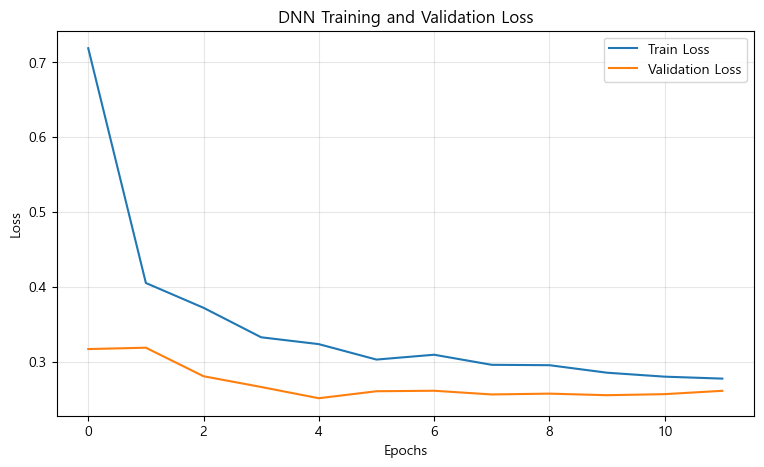

,실험,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN,FP
0,Optuna DNN (기본 구조 및 전처리 최적화),0.8976,0.6565,0.7082,0.6814,0.9228,89,113


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.20,0.7988,0.4283,0.9016,0.5808
1,0.25,0.8373,0.4856,0.8820,0.6263
2,0.30,0.8550,0.5193,0.8361,0.6407
3,0.35,0.8733,0.5626,0.8098,0.6640
4,0.40,0.8860,0.5995,0.7902,0.6818
5,0.45,0.8951,0.6346,0.7574,0.6906
6,0.50,0.8971,0.6723,0.6525,0.6622
7,0.55,0.8941,0.7202,0.5148,0.6004
8,0.60,0.8870,0.7412,0.4131,0.5305


In [ ]:
# 1. 라이브러리 및 내부 검증 분리
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import optuna
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

X_dtr, X_temp, y_dtr, y_temp = train_test_split(X_fit, y_fit, test_size=0.4, stratify=y_fit, random_state=42)
X_des, X_dval, y_des, y_dval = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
y_dtr = np.asarray(y_dtr).astype('float32')
y_des = np.asarray(y_des).astype('float32')
y_dval = np.asarray(y_dval).astype('float32')

# 2. 파생변수 생성
def dnn_features(X, feature_mode):
    X = X.copy()
    if feature_mode in ['basic', 'extended']:
        X['상품페이지_평균체류시간'] = X['ProductRelated_Duration'] / (X['ProductRelated'] + 1)
        X['상품페이지_방문비율'] = X['ProductRelated'] / (X['Administrative'] + X['Informational'] + X['ProductRelated'] + 1)
    if feature_mode == 'extended':
        X['전체_방문페이지'] = X['Administrative'] + X['Informational'] + X['ProductRelated']
        X['전체_체류시간'] = X['Administrative_Duration'] + X['Informational_Duration'] + X['ProductRelated_Duration']
        X['전체_평균체류시간'] = X['전체_체류시간'] / (X['전체_방문페이지'] + 1)
        X['상품페이지_체류비율'] = X['ProductRelated_Duration'] / (X['전체_체류시간'] + 1)
    return X

# 3. Scaler 선택
def get_scaler(name):
    if name == 'standard':
        return StandardScaler()
    if name == 'minmax':
        return MinMaxScaler()
    return RobustScaler()

# 4. DNN 모델 생성
def make_dnn(units1, units2, dropout, lr, input_size):
    model = Sequential([
        tf.keras.Input(shape=(input_size,)),
        Dense(units1, activation='relu'),
        Dropout(dropout),
        Dense(units2, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='binary_crossentropy')
    return model

# 5. Threshold 선택 
def find_threshold(y_true, proba):
    results = []
    for t in np.arange(0.25, 0.66, 0.01):
        pred = (proba >= t).astype(int)
        acc = accuracy_score(y_true, pred)
        pre = precision_score(y_true, pred, zero_division=0)
        rec = recall_score(y_true, pred, zero_division=0)
        f1 = f1_score(y_true, pred, zero_division=0)
        score = f1 - 2 * max(0, 0.90 - acc) - 2 * max(0, 0.70 - pre) - 2 * max(0, 0.70 - rec)
        results.append((score, round(float(t), 2)))
    return max(results)

# 6. Optuna 최적화
def dnn_objective(trial):
    units1 = trial.suggest_categorical('units1', [32, 64, 128])
    units2 = trial.suggest_categorical('units2', [16, 32, 64])
    dropout = trial.suggest_categorical('dropout', [0.1, 0.2, 0.3])
    lr = trial.suggest_categorical('learning_rate', [0.001, 0.0005])
    batch = trial.suggest_categorical('batch_size', [32, 64])
    weight = trial.suggest_categorical('weight', [1.0, 1.2, 1.5, 2.0])

    
    scaler_name = trial.suggest_categorical('scaler', ['standard', 'minmax', 'robust'])
    feature_mode = trial.suggest_categorical('feature_mode', ['none', 'basic', 'extended'])
    scaler = get_scaler(scaler_name)

    X_train_dnn = scaler.fit_transform(dnn_features(X_dtr, feature_mode)).astype('float32')
    X_early_dnn = scaler.transform(dnn_features(X_des, feature_mode)).astype('float32')
    X_valid_dnn = scaler.transform(dnn_features(X_dval, feature_mode)).astype('float32')
    
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)
    model = make_dnn(units1, units2, dropout, lr, X_train_dnn.shape[1])
    model.fit(X_train_dnn, y_dtr, epochs=50, batch_size=batch, verbose=0,
              validation_data=(X_early_dnn, y_des), class_weight={0: 1.0, 1: float(weight)},
              callbacks=[EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)])
    proba = model.predict(X_valid_dnn, verbose=0).ravel()
    score, threshold = find_threshold(y_dval, proba)
    trial.set_user_attr('threshold', threshold)
    return score

# 7. Optuna 실행
dnn_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
dnn_study.optimize(dnn_objective, n_trials=50)
dnn_best = dnn_study.best_params
best_threshold = dnn_study.best_trial.user_attrs['threshold']
print('DNN 최적 설정:', dnn_best)
print('Threshold:', best_threshold)

# 8. 최적 설정으로 재학습
final_scaler = get_scaler(dnn_best['scaler'])
X_dnn_fit = final_scaler.fit_transform(dnn_features(X_fit, dnn_best['feature_mode'])).astype('float32')
X_dnn_valid = final_scaler.transform(dnn_features(X_valid, dnn_best['feature_mode'])).astype('float32')
y_dnn_fit = np.asarray(y_fit).astype('float32')
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
dnn_model = make_dnn(dnn_best['units1'], dnn_best['units2'], dnn_best['dropout'],
                     dnn_best['learning_rate'], X_dnn_fit.shape[1])
history = dnn_model.fit(X_dnn_fit, y_dnn_fit, epochs=50, batch_size=dnn_best['batch_size'],
                        verbose=0, validation_split=0.2,
                        class_weight={0: 1.0, 1: float(dnn_best['weight'])},
                        callbacks=[EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)])



# 9. Loss 그래프
plt.figure(figsize=(9, 5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('DNN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 10. Validation 평가
dnn_proba = dnn_model.predict(X_dnn_valid, verbose=0).ravel()
dnn_ensemble_proba = dnn_proba.copy()
dnn_pred = (dnn_proba >= best_threshold).astype(int)
dnn_tn, dnn_fp, dnn_fn, dnn_tp = confusion_matrix(y_valid, dnn_pred, labels=[0, 1]).ravel()
dnn_optuna_result = {
    '실험': 'Optuna DNN (기본 구조 및 전처리 최적화)',
    'Accuracy': accuracy_score(y_valid, dnn_pred),
    'Precision': precision_score(y_valid, dnn_pred, zero_division=0),
    'Recall': recall_score(y_valid, dnn_pred, zero_division=0),
    'F1-score': f1_score(y_valid, dnn_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_valid, dnn_proba), 'FN': dnn_fn, 'FP': dnn_fp
}
display(pd.DataFrame([dnn_optuna_result]).round(4))

# 11. Threshold별 성능 비교 (외부 Validation 진단용)
threshold_results = []
for t in np.arange(0.20, 0.61, 0.05):
    pred = (dnn_proba >= t).astype(int)
    threshold_results.append({
        'Threshold': round(float(t), 2), 'Accuracy': accuracy_score(y_valid, pred),
        'Precision': precision_score(y_valid, pred, zero_division=0),
        'Recall': recall_score(y_valid, pred, zero_division=0),
        'F1-score': f1_score(y_valid, pred, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

## 48-1. Optuna 실험 결과 그래프

실험별 점수와 누적 최고 점수를 비교한다.

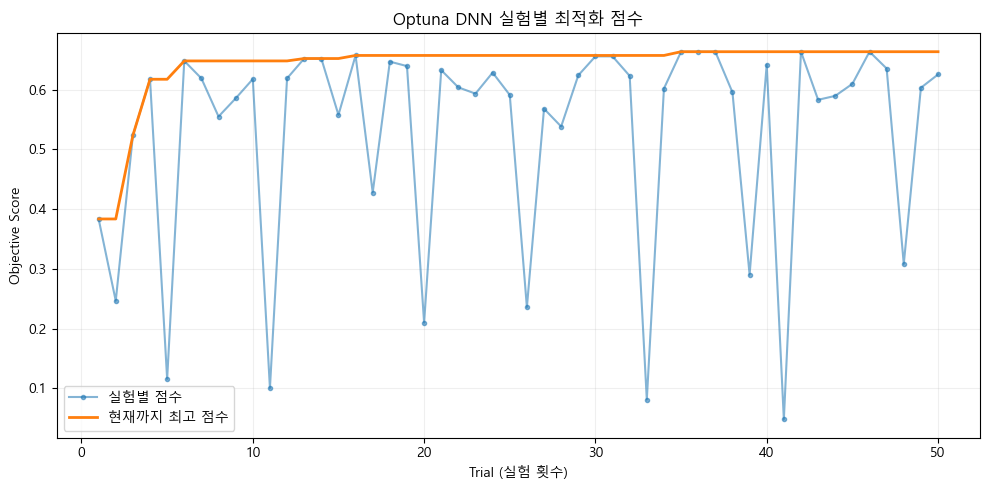

완료한 실험 수: 50
최고 Objective Score: 0.6632


In [47]:
# 1. Optuna 실험별 점수 확인
trial_scores = [(trial.number + 1, trial.value) for trial in dnn_study.trials if trial.value is not None]
trial_numbers = [number for number, score in trial_scores]
scores = [score for number, score in trial_scores]
best_scores = np.maximum.accumulate(scores)

plt.figure(figsize=(10, 5))
plt.plot(trial_numbers, scores, marker='o', markersize=3, alpha=0.55, label='실험별 점수')
plt.plot(trial_numbers, best_scores, linewidth=2, label='현재까지 최고 점수')
plt.title('Optuna DNN 실험별 최적화 점수')
plt.xlabel('Trial (실험 횟수)')
plt.ylabel('Objective Score')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('완료한 실험 수:', len(trial_scores))
print('최고 Objective Score:', round(float(max(scores)), 4))


## 49. XGBoost + DNN 앙상블 비교

XGBoost 70%, DNN 30%로 예측 확률을 결합하고 단독 모델과 성능을 비교한다.

In [48]:
# 1. 두 모델의 Validation 예측 확률 준비

xgb_ensemble_proba = xgb_optuna.predict_proba(X_valid_two)[:, 1]
dnn_ensemble_proba = np.asarray(dnn_ensemble_proba).ravel()
y_ensemble = np.asarray(y_valid).astype(int).ravel()

# 2. 고정 가중치로 앙상블 예측
# X_valid_two와 X_dnn_valid는 동일한 X_valid에서 행 순서를 유지해 생성됨
xgb_weight = 0.7
dnn_weight = 0.3
ensemble_threshold = 0.40
ensemble_proba = xgb_weight * xgb_ensemble_proba + dnn_weight * dnn_ensemble_proba

# 3. 단독 모델과 앙상블 성능 비교
def ensemble_metrics(name, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_ensemble, pred, labels=[0, 1]).ravel()
    return {
        '실험': name, 'Threshold': threshold,
        'Accuracy': accuracy_score(y_ensemble, pred),
        'Precision': precision_score(y_ensemble, pred, zero_division=0),
        'Recall': recall_score(y_ensemble, pred, zero_division=0),
        'F1-score': f1_score(y_ensemble, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_ensemble, proba), 'FN': fn, 'FP': fp
    }

ensemble_compare = pd.DataFrame([
    ensemble_metrics('Optuna XGBoost (현재 노트북)', xgb_ensemble_proba, 0.50),
    ensemble_metrics('Optuna DNN 최적화', dnn_ensemble_proba, best_threshold),
    ensemble_metrics('XGBoost 70% + DNN 30%', ensemble_proba, ensemble_threshold)
])
display(ensemble_compare.round(4))

# 4. 앙상블 비교 결과 정리
print('앙상블 가중치와 Threshold는 Validation 결과를 보고 최적화한 값이 아닙니다.')

,실험,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN,FP
0,Optuna XGBoost (현재 노트북),0.50,0.9047,0.6767,0.7344,0.7044,0.9275,81,107
1,Optuna DNN 최적화,0.48,0.8976,0.6565,0.7082,0.6814,0.9228,89,113
2,XGBoost 70% + DNN 30%,0.40,0.8936,0.6221,0.7934,0.6974,0.9286,63,147


앙상블 가중치와 Threshold는 Validation 결과를 보고 최적화한 값이 아닙니다.


## 50. 최종 XGBoost Test 평가

Validation에서 선택한 XGBoost를 Threshold 0.50으로 평가한다.

In [49]:
# 1. Validation에서 선정한 모델 확인
print('선정 모델: Optuna XGBoost (현재 노트북)')
print('Validation: Accuracy 0.9047 | Precision 0.6767 | Recall 0.7344 | F1-score 0.7044')
print('고정 Threshold: 0.50')

# 2. 최종 모델과 Test 데이터 준비

# 학습할 때 삭제한 컬럼을 Test에서도 동일하게 삭제
X_test_two = X_test.drop(columns=two_drop_cols)

# 3. 최종 Test 예측 (Threshold 0.50 고정)
final_threshold = 0.50
test_proba = xgb_optuna.predict_proba(X_test_two)[:, 1]
test_pred = (test_proba >= final_threshold).astype(int)

# 4. 최종 Test 평가 지표 계산
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
final_test_result = {
    '모델': 'Optuna XGBoost',
    'Threshold': final_threshold,
    'Accuracy': accuracy_score(y_test, test_pred),
    'Precision': precision_score(y_test, test_pred, zero_division=0),
    'Recall': recall_score(y_test, test_pred, zero_division=0),
    'F1-score': f1_score(y_test, test_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, test_proba),
    'FN': fn,
    'FP': fp
}

print('최종 Test 평가 결과')
display(pd.DataFrame([final_test_result]).round(4))

# 5. 혼동행렬 확인
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
print('혼동행렬 (행: 실제값 0/1, 열: 예측값 0/1)')
display(pd.DataFrame(cm, index=['실제 비구매', '실제 구매'],
                     columns=['예측 비구매', '예측 구매']))

선정 모델: Optuna XGBoost (현재 노트북)
Validation: Accuracy 0.9047 | Precision 0.6767 | Recall 0.7344 | F1-score 0.7044
고정 Threshold: 0.50
최종 Test 평가 결과


,모델,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN,FP
0,Optuna XGBoost,0.5,0.8933,0.657,0.6518,0.6544,0.9271,133,130


혼동행렬 (행: 실제값 0/1, 열: 예측값 0/1)


,예측 비구매,예측 구매
실제 비구매,1954,130
실제 구매,133,249


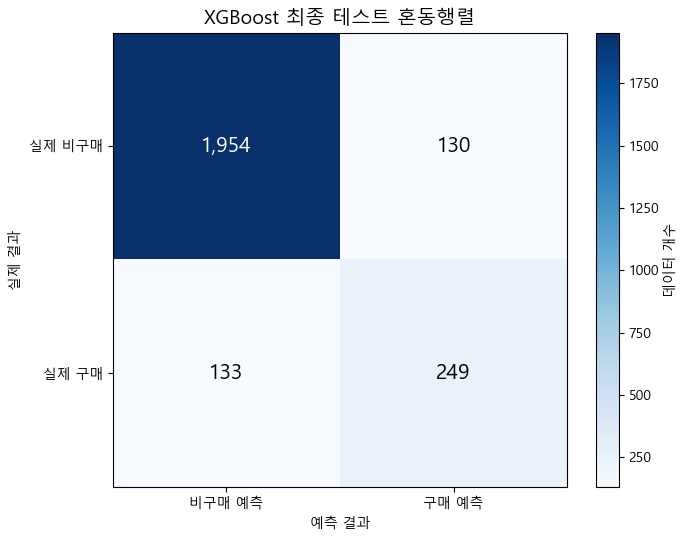

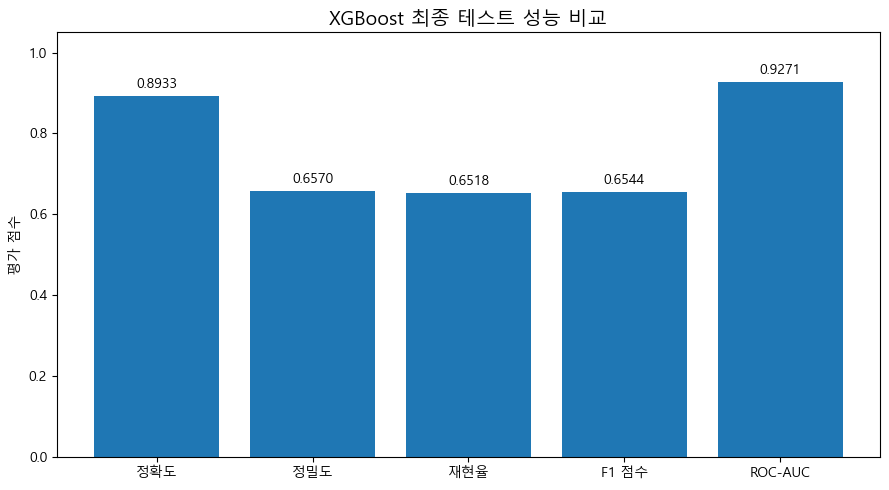

In [ ]:
import matplotlib.font_manager as fm
font_names = [font.name for font in fm.fontManager.ttflist]
if 'Malgun Gothic' in font_names:
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif 'NanumGothic' in font_names:
    plt.rcParams['font.family'] = 'NanumGothic'
elif 'Noto Sans CJK KR' in font_names:
    plt.rcParams['font.family'] = 'Noto Sans CJK KR'
plt.rcParams['axes.unicode_minus'] = False

# 8. 최종 Test 혼동행렬 그래프
plt.figure(figsize=(7, 5.5))
plt.imshow(cm, cmap='Blues')
plt.colorbar(label='데이터 개수')
plt.xticks([0, 1], ['비구매 예측', '구매 예측'])
plt.yticks([0, 1], ['실제 비구매', '실제 구매'])
plt.title('XGBoost 최종 테스트 혼동행렬', fontsize=14)
plt.xlabel('예측 결과')
plt.ylabel('실제 결과')
for i in range(2):
    for j in range(2):
        plt.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=15,
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

# 9. 최종 Test 평가 지표 그래프
metric_keys = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
metric_names = ['정확도', '정밀도', '재현율', 'F1 점수', 'ROC-AUC']
metric_values = [final_test_result[name] for name in metric_keys]
plt.figure(figsize=(9, 5))
plt.bar(metric_names, metric_values)
plt.ylim(0, 1.05)
plt.title('XGBoost 최종 테스트 성능 비교', fontsize=14)
plt.ylabel('평가 점수')
for i, value in enumerate(metric_values):
    plt.text(i, value + 0.02, f'{value:.4f}', ha='center')
plt.tight_layout()
plt.show()

In [51]:
print(df['Month'].value_counts().sort_index())

Aug      433
Dec     1727
Feb      184
Jul      432
June     288
Mar     1907
May     3364
Nov     2998
Oct      549
Sep      448
Name: Month, dtype: int64


# DAY 6. 최종 모델 분석

최종 Test 성능, 오분류 사례, 변수 중요도를 분석하고 결과를 정리한다.

# 51. 최종 후보 모델 비교

Validation 결과

| 모델 | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| DNN | 0.8951 | 0.6512 | 0.6918 | 0.6709 | 0.9253 |
| Optuna XGBoost | 0.9047 | 0.6767 | 0.7344 | 0.7044 | 0.9275 |
| XGBoost 70% + DNN 30% | 0.8976 | 0.6381 | 0.7803 | 0.7021 | 0.9288 |

앙상블은 Recall이 가장 높았지만 Accuracy와 F1-score가 더 높은 XGBoost를 최종 모델로 선택했다.

위 수치는 이전 실험 기록이며 DNN 간소화 후 다시 학습하면 결과가 달라질 수 있다.

# 52. 최종 Test 결과 해석

Test 결과: Accuracy 0.8933, Precision 0.6570, Recall 0.6518, F1-score 0.6544, ROC-AUC 0.9271

혼동행렬: TN 1954, FP 130, FN 133, TP 249

Validation보다 Recall과 F1-score가 낮아졌지만 ROC-AUC는 비슷하게 유지됐다.

In [52]:
# 1. 최종 Test 결과 표 확인
display(pd.DataFrame([final_test_result]).round(4))
display(pd.DataFrame(cm, index=['실제 비구매', '실제 구매'], columns=['예측 비구매', '예측 구매']))


,모델,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN,FP
0,Optuna XGBoost,0.5,0.8933,0.657,0.6518,0.6544,0.9271,133,130


,예측 비구매,예측 구매
실제 비구매,1954,130
실제 구매,133,249


# 53. 오분류 데이터 추출

FP와 FN에 해당하는 세션을 원본 데이터에서 추출한다.

In [53]:
# 1. Test 실제값과 예측값을 원본 데이터에 연결
error_df = df.loc[X_test.index].copy()
error_df['실제구매'] = np.asarray(y_test).astype(int)
error_df['예측구매'] = np.asarray(test_pred).astype(int)
error_df['구매예측확률'] = np.asarray(test_proba)

# 2. FP와 FN 구분
fp_df = error_df[(error_df['실제구매'] == 0) & (error_df['예측구매'] == 1)].copy()
fn_df = error_df[(error_df['실제구매'] == 1) & (error_df['예측구매'] == 0)].copy()

print('FP 개수:', len(fp_df))
print('FN 개수:', len(fn_df))
print('FP')
display(fp_df[['VisitorType', 'Month', 'TrafficType', 'PageValues', 'ExitRates', '구매예측확률']].head(10))
print('FN')
display(fn_df[['VisitorType', 'Month', 'TrafficType', 'PageValues', 'ExitRates', '구매예측확률']].head(10))


FP 개수: 130
FN 개수: 133
FP


,VisitorType,Month,TrafficType,PageValues,ExitRates,구매예측확률
10682,Returning_Visitor,Nov,2,9.269828,0.027928,0.548676
6922,Returning_Visitor,Nov,1,20.139076,0.046667,0.722200
12027,Returning_Visitor,Nov,2,2.270358,0.011201,0.514777
10044,Returning_Visitor,Dec,2,1.795451,0.010435,0.694176
4450,Returning_Visitor,May,5,12.152105,0.069737,0.653374
9486,Returning_Visitor,Nov,2,15.955388,0.008689,0.806151
4433,New_Visitor,May,5,14.737091,0.023232,0.665994
1622,Returning_Visitor,Mar,2,24.130731,0.027916,0.671493
4987,Returning_Visitor,May,3,21.595200,0.032000,0.551903
2426,Returning_Visitor,May,2,33.650100,0.012500,0.796836


FN


,VisitorType,Month,TrafficType,PageValues,ExitRates,구매예측확률
11507,New_Visitor,Dec,20,0.000000,0.053333,0.086954
7322,Returning_Visitor,Jul,3,0.000000,0.004063,0.040039
2335,Returning_Visitor,May,2,8.011553,0.025596,0.423094
11798,Returning_Visitor,Nov,3,0.000000,0.066667,0.064376
320,Returning_Visitor,Mar,1,7.103021,0.038373,0.461171
9498,Returning_Visitor,Nov,2,0.000000,0.019913,0.216530
8045,Returning_Visitor,Nov,2,0.000000,0.038889,0.130958
10176,Returning_Visitor,Nov,8,0.000000,0.010521,0.364925
7841,New_Visitor,Nov,5,0.000000,0.022222,0.240718
7319,New_Visitor,Jul,6,0.000000,0.006712,0.108210


# 54. 방문자 유형 및 월별 오류 분석

FP와 FN 건수 및 각 그룹의 오류 비율을 비교한다.

In [54]:
# 1. 방문자 유형별 오류 비율
for feature in ['VisitorType', 'Month', 'TrafficType']:
    summary = error_df.groupby(feature, dropna=False).apply(
        lambda g: pd.Series({
            '전체 세션': len(g),
            '실제 비구매': (g['실제구매'] == 0).sum(),
            '실제 구매': (g['실제구매'] == 1).sum(),
            'FP': ((g['실제구매'] == 0) & (g['예측구매'] == 1)).sum(),
            'FN': ((g['실제구매'] == 1) & (g['예측구매'] == 0)).sum()
        })
    )
    summary['FP 비율(%)'] = (summary['FP'] / summary['실제 비구매'].replace(0, np.nan) * 100).round(2)
    summary['FN 비율(%)'] = (summary['FN'] / summary['실제 구매'].replace(0, np.nan) * 100).round(2)
    print(feature, '별 오류 분석')
    display(summary.sort_values('FN', ascending=False))


VisitorType 별 오류 분석


,전체 세션,실제 비구매,실제 구매,FP,FN,FP 비율(%),FN 비율(%)
VisitorType,,,,,,,
Returning_Visitor,2108,1818,290,121,113,6.66,38.97
New_Visitor,347,258,89,9,20,3.49,22.47
Other,11,8,3,0,0,0.00,0.00


Month 별 오류 분석


,전체 세션,실제 비구매,실제 구매,FP,FN,FP 비율(%),FN 비율(%)
Month,,,,,,,
Nov,638,464,174,49,72,10.56,41.38
May,661,588,73,25,19,4.25,26.03
Jul,88,68,20,5,11,7.35,55.00
Aug,91,76,15,8,8,10.53,53.33
Dec,336,304,32,25,8,8.22,25.00
Mar,369,336,33,5,6,1.49,18.18
Oct,105,88,17,4,4,4.55,23.53
June,60,54,6,3,3,5.56,50.00
Sep,80,69,11,6,2,8.70,18.18


TrafficType 별 오류 분석


,전체 세션,실제 비구매,실제 구매,FP,FN,FP 비율(%),FN 비율(%)
TrafficType,,,,,,,
2,778,627,151,51,53,8.13,35.10
1,517,450,67,25,27,5.56,40.30
3,398,361,37,14,12,3.88,32.43
4,203,169,34,17,10,10.06,29.41
6,94,81,13,3,8,3.70,61.54
11,52,38,14,0,6,0.00,42.86
8,75,54,21,2,5,3.70,23.81
10,80,65,15,5,5,7.69,33.33
5,45,36,9,7,3,19.44,33.33


,FP,FN
1,25,27
2,51,53
3,14,12
4,17,10
5,7,3
6,3,8
8,2,5
10,5,5
11,0,6
13,5,2


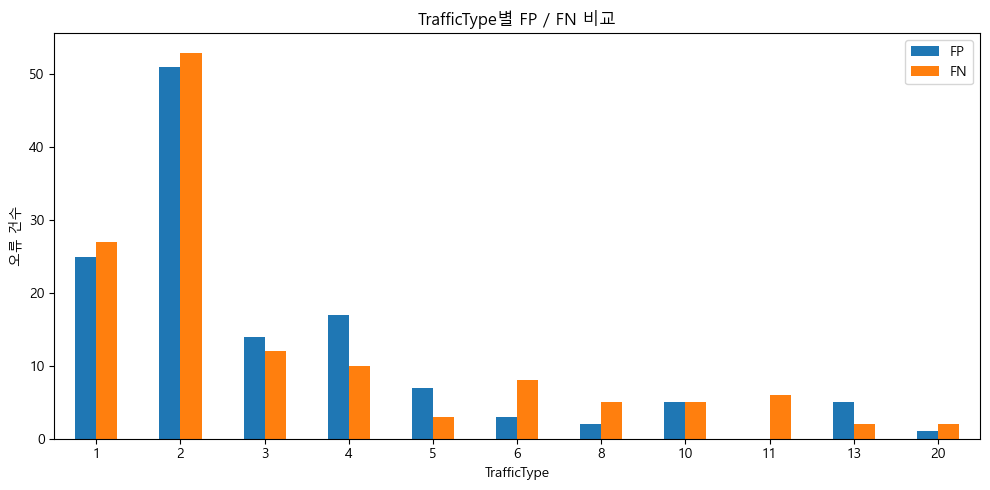

In [55]:
# 1. TrafficType별 FP와 FN 개수 계산
traffic_fp = fp_df['TrafficType'].value_counts()
traffic_fn = fn_df['TrafficType'].value_counts()

# 2. 그래프용 데이터 만들기
traffic_result = pd.DataFrame({
    'FP': traffic_fp,
    'FN': traffic_fn
}).fillna(0).astype(int).sort_index()

display(traffic_result)

# 3. 막대그래프
traffic_result.plot(kind='bar', figsize=(10, 5))

plt.title('TrafficType별 FP / FN 비교')
plt.xlabel('TrafficType')
plt.ylabel('오류 건수')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


VisitorType
New_Visitor          22.47
Other                 0.00
Returning_Visitor    38.97
dtype: float64

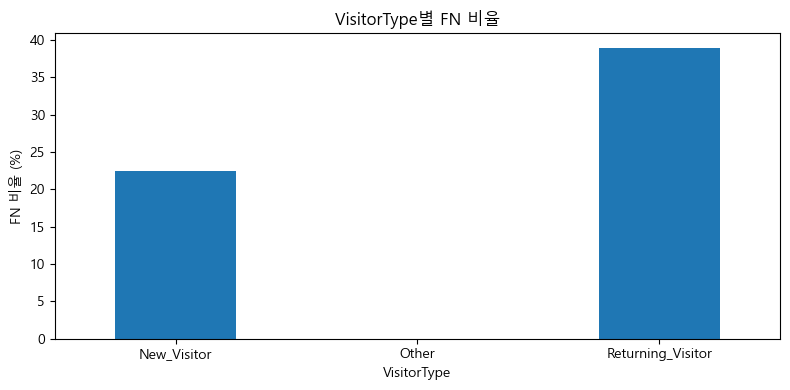

In [56]:

# 1. 방문자 유형별 실제 구매 고객 수
visitor_buy = error_df[error_df['실제구매'] == 1].groupby('VisitorType').size()

# 2. 방문자 유형별 FN 개수
visitor_fn = fn_df.groupby('VisitorType').size()

# 3. FN 비율 계산
visitor_result = (visitor_fn / visitor_buy * 100).fillna(0)

display(visitor_result.round(2))

# 4. 막대그래프
visitor_result.plot(kind='bar', figsize=(8, 4))

plt.title('VisitorType별 FN 비율')
plt.xlabel('VisitorType')
plt.ylabel('FN 비율 (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 55. 오분류 세션의 페이지 행동 비교

PageValues, ProductRelated, ProductRelated_Duration, BounceRates, ExitRates를 비교한다.

집단별 주요 행동 지표 평균


,PageValues,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
실제 비구매 전체,2.0868,29.3748,1080.6537,0.0241,0.0458
FP,26.9678,52.8769,2049.1754,0.0075,0.0228
실제 구매 전체,25.2052,51.7853,2028.9235,0.0064,0.0218
FN,3.3784,61.4737,2364.7849,0.0110,0.0298


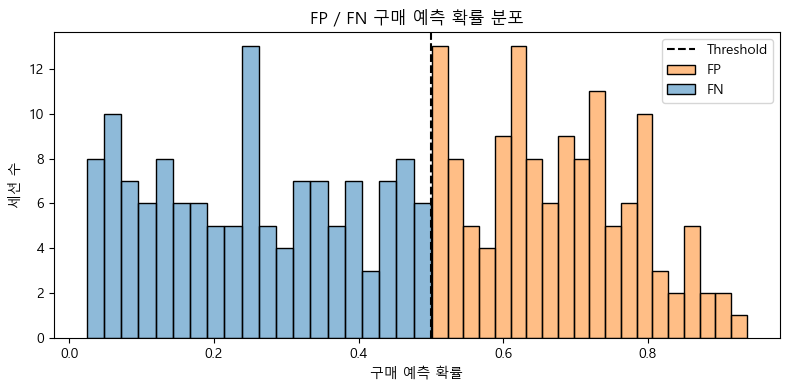

In [57]:
# 1. 실제 비구매/구매와 오분류 집단의 행동 지표 비교
behavior_cols = ['PageValues', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']
behavior_groups = {
    '실제 비구매 전체': error_df[error_df['실제구매'] == 0],
    'FP': fp_df,
    '실제 구매 전체': error_df[error_df['실제구매'] == 1],
    'FN': fn_df
}
behavior_summary = pd.DataFrame({name: group[behavior_cols].mean() for name, group in behavior_groups.items()}).T
print('집단별 주요 행동 지표 평균')
display(behavior_summary.round(4))

# 2. 구매 예측 확률 분포 확인
plt.figure(figsize=(8, 4))
sns.histplot(fp_df['구매예측확률'], color='tab:orange', label='FP', bins=20, alpha=0.5)
sns.histplot(fn_df['구매예측확률'], color='tab:blue', label='FN', bins=20, alpha=0.5)
plt.axvline(final_threshold, color='black', linestyle='--', label='Threshold')
plt.title('FP / FN 구매 예측 확률 분포')
plt.xlabel('구매 예측 확률')
plt.ylabel('세션 수')
plt.legend()
plt.tight_layout()
plt.show()


# 56. XGBoost 변수 중요도

최종 모델의 변수 중요도 상위 15개를 확인한다.

,Feature,Importance
0,PageValues,0.3581
1,Month_Nov,0.0693
2,Month_May,0.0487
3,Month_Mar,0.0484
4,VisitorType_Returning_Visitor,0.0389
5,ExitRates,0.0297
6,Administrative,0.0282
7,TrafficType_2,0.0267
8,ProductRelated,0.0253
9,TrafficType_13,0.0240


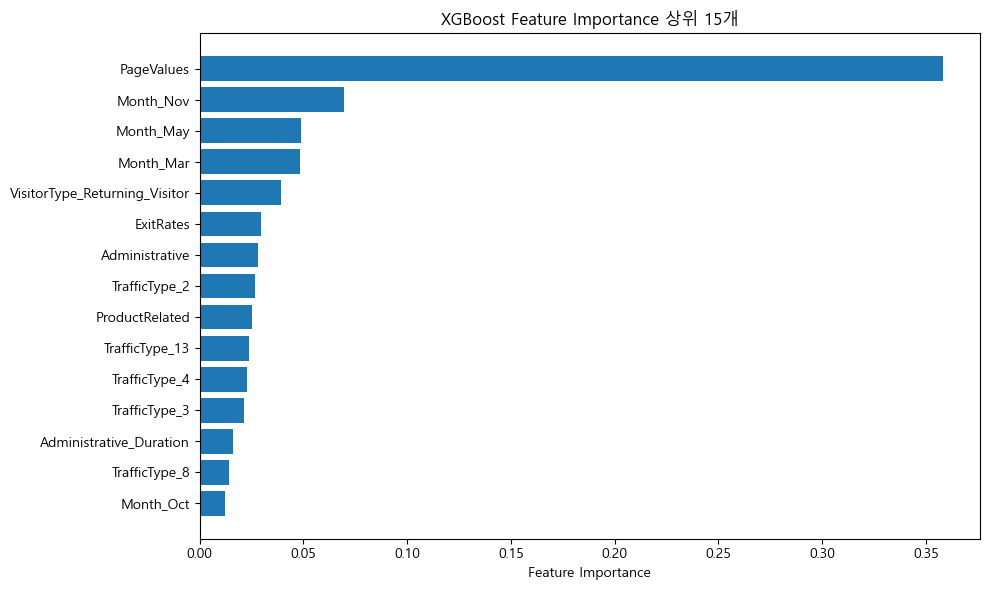

In [58]:
# 1. 최종 XGBoost 변수 중요도 추출

importance_df = pd.DataFrame({
    'Feature': X_fit_two.columns,
    'Importance': xgb_optuna.feature_importances_
}).sort_values('Importance', ascending=False)

# 2. 상위 15개 변수 표와 그래프
top_features = importance_df.head(15).sort_values('Importance')
display(importance_df.head(15).reset_index(drop=True).round(4))
plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.title('XGBoost Feature Importance 상위 15개')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()


# 57. EDA 결과와 Feature Importance 비교

최종 XGBoost 변수 중요도 상위 항목은 PageValues 0.3581, Month_Nov 0.0693, Month_May 0.0487, Month_Mar 0.0484, VisitorType_Returning_Visitor 0.0389, ExitRates 0.0297 순으로 확인되었다.

- 중요도가 가장 높은 변수는 PageValues이며 다른 변수보다 높은 값을 보였다.
- EDA에서 구매 여부와 관련이 있어 보였던 PageValues와 ExitRates가 최종 모델에서도 중요한 변수로 나타났다.
- Month_Nov 등 방문 월 관련 변수가 상위에 나타났다. 단순 상관관계 분석에서 눈에 띄는 변수와 모델에서 중요하게 사용한 변수가 완전히 같지는 않았다.
- ProductRelated_Duration은 최종 XGBoost 학습에서 삭제한 컬럼이므로 이 모델의 중요도 순위에 나타나지 않는다.
- Feature Importance는 모델에서 변수를 활용한 정도를 나타내며 구매의 원인이나 예측 방향을 직접 알려주지는 않는다.

위 값은 저장된 실행 결과를 기준으로 작성했다. 모델을 다시 학습했다면 새 출력에 맞춰 확인한다.

# 58. DAY 6 고찰

1. 최종 모델을 선택한 가장 중요한 이유는 무엇인가?
- Validation에서 비교한 후보 중 Optuna XGBoost의 Accuracy 0.9047과 F1-score 0.7044가 가장 높았기 때문이다. 앙상블의 Recall은 더 높았지만 FP가 증가했다.

2. 성능 외에 모델 선택에서 고려한 요소는 무엇인가?
- 단일 XGBoost는 DNN과 결합한 앙상블보다 구조가 단순하며 Feature Importance를 통해 주요 변수를 확인할 수 있다.

3. 모델이 반복적으로 잘못 예측한 데이터의 특징은 무엇인가?
- 최종 Test에서 FP 130건, FN 133건이 발생했다.
- FP는 실제 구매하지 않았지만 PageValues 평균이 약 26.97로 실제 비구매 전체 평균 2.09보다 높았다. 구매 고객과 비슷한 행동을 보인 비구매 세션을 구매로 예측한 경우가 있었다.
- FN은 실제 구매했지만 PageValues 평균이 약 3.38로 실제 구매 전체 평균 25.21보다 낮았다. 상품 관련 페이지 방문 횟수 평균은 약 61.47로 높은 편이었다.
- 재방문자와 11월에 오분류 건수가 많았다. 다만 해당 집단의 전체 세션 수와 실제 구매 건수도 함께 고려해야 한다.

4. 이번 프로젝트에서 가장 효과적이었던 개선 방법은 무엇인가?
- 머신러닝에서 컬럼 삭제, 구매 고객 가중치, 파생변수, Optuna 하이퍼파라미터 탐색을 비교했고 최종적으로 Optuna XGBoost가 좋은 성능 균형을 보였다.
- 딥러닝에서는 구조 변경, 스케일링, 파생변수, Batch Normalization, L2 및 손실 함수를 비교했다. Optuna가 최종 선택한 DNN 손실 함수는 Focal Loss가 아니라 Binary Crossentropy였다.

5. 실제 서비스에 적용한다면 추가로 개선해야 할 점은 무엇인가?
- 방문 시점이 다른 데이터로 성능을 다시 확인하고 구매율 변화와 데이터 분포 변화를 점검해야 한다.
- FN과 FP의 비용을 서비스 목적에 맞춰 비교하고 Threshold는 Validation에서만 조정해야 한다.
- 이전 실험에서 Test를 탐색적으로 사용한 이력이 있으므로 실제 적용 전에는 완전히 독립적인 평가 데이터를 추가로 확보할 필요가 있다.

# 59. 최종 결과 정리 및 발표 준비

문제
- 온라인 쇼핑 세션의 행동 데이터를 활용하여 구매 여부를 예측했다.

데이터에서 발견한 점
- PageValues와 이탈 관련 지표는 구매 여부에 따라 차이를 보였다. 11월에는 구매 세션이 많이 나타났다.

실험한 모델
- Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost, MLP, DNN, XGBoost와 DNN 앙상블을 비교했다.

성능 개선 방법
- 컬럼 삭제, Scaling, 파생변수, 구매 고객 가중치, Optuna, DNN 구조 변경, 앙상블을 실험했다.

최종 모델
- Validation 비교 결과 Optuna XGBoost를 선택했다.
- 최종 Test에서는 Accuracy 0.8933, Precision 0.6570, Recall 0.6518, F1-score 0.6544, ROC-AUC 0.9271을 기록했다.

오류 분석과 모델 해석
- 최종 Test에서 FP 130건과 FN 133건을 확인했다.
- FP 집단은 PageValues가 비구매 전체 평균보다 높았고, FN 집단은 PageValues가 구매 전체 평균보다 낮았다.
- Feature Importance에서 PageValues가 가장 높았고, Month_Nov, Month_May, Month_Mar, 재방문자 여부, ExitRates가 뒤를 이었다.

한계 및 추가 개선
- Validation 대비 Test에서 Recall과 F1-score가 낮아졌다. 다른 시점의 데이터와 독립적인 최종 평가 데이터로 재검증할 필요가 있다.
- 실제 서비스에서는 FP와 FN의 비용을 검토하여 적절한 운영 Threshold를 선택할 필요가 있다.

DNN 구조를 단순화한 뒤에는 새로운 Validation 성능과 앙상블 성능을 다시 확인한다. 기존 수치는 이전 실험 기록이다.